# Explore every column of the Norwegian equity dataset

This notebook explains and visualizes **all 49 columns** in
`BMG9156K1018_10.09.2026_14.59.34.csv`. This is the **only input dataset**;
there are no downloads, joins to other files, or external data sources.
The filename names one ISIN, but the file contains a historical panel of many securities.

**How to read the explanations.** The CSV contains column names and values, but no
provider data dictionary. Descriptions below distinguish directly observed properties,
conventional interpretations of names, and definitions that remain unverified.
In particular, accounting units, reporting dates, adjustment conventions, and factor
construction cannot be established from column names alone. The empirical checks at
the end test candidate relationships; they do not supply missing provider documentation.

Run the notebook from top to bottom using the existing `sandbox/.venv` environment
(pandas, NumPy, Matplotlib, and IPython). It loads the full CSV into memory.
No rows are filtered from the main analysis, and no values are imputed or repaired.

## 1. Load this file and establish its scope

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_FILE = "BMG9156K1018_10.09.2026_14.59.34.csv"
# Support launching Jupyter from the repository root or from sandbox/.
root = Path.cwd().parent if Path.cwd().name == "sandbox" else Path.cwd()
data_path = root / "Data" / DATA_FILE
data = pd.read_csv(data_path, sep=";", decimal=",", low_memory=False)
data["Date"] = pd.to_datetime(data["Date"], format="%Y-%m-%d", errors="raise")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 16)

print(f"Only input: {data_path.resolve()}")
print(f"Rows: {len(data):,} | Columns: {data.shape[1]}")
print(f"Dates: {data['Date'].min():%Y-%m-%d} to {data['Date'].max():%Y-%m-%d}")
print(f"Distinct nonmissing ISINs: {data['ISIN'].nunique():,}")
print(f"Distinct nonmissing CompanyId values: {data['CompanyId'].nunique():,}")
display(data.head())

Only input: /Users/pasha/Desktop/master/master_thesis/Data/BMG9156K1018_10.09.2026_14.59.34.csv
Rows: 1,876,617 | Columns: 49
Dates: 1980-01-02 to 2026-09-08
Distinct nonmissing ISINs: 1,133
Distinct nonmissing CompanyId values: 740


,Date,Internal code,SecurityId,CompanyId,Symbol,ISIN,Name,BestBidPrice,...,Sector,IN_OSEBX,Equity,Debt,Earnings,debt_ratio,PE,ID
0,2019-07-15,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,80.05,...,Industrials,0,NaN,NaN,NaN,NaN,NaN,691997
1,2019-07-16,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,80.55,...,Industrials,0,NaN,NaN,NaN,NaN,NaN,692113
2,2019-07-17,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,80.40,...,Industrials,0,NaN,NaN,NaN,NaN,NaN,681877
3,2019-07-18,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,77.40,...,Industrials,0,NaN,NaN,NaN,NaN,NaN,681961
4,2019-07-19,2014128.0,1304857.0,12720.0,2020,BMG9156K1018,2020 Bulkers,78.00,...,Industrials,0,NaN,NaN,NaN,NaN,NaN,692452


## 2. Availability and plotting conventions

The table counts missing values and distinct nonmissing values in the parsed CSV.
Numeric identifiers are treated as labels, rather than quantities to average.
`NaN` counts do **not** include numeric placeholder codes such as `-999999999`.
Zero is retained: its meaning differs between prices, dividends, volume, and returns.

All univariate numeric summaries are **row weighted**. A security with more history
contributes more observations, and a market-wide value repeated across securities is
counted repeatedly. These are descriptive panel distributions, not independent samples,
equal-weighted company estimates, or daily market-return distributions.

For each numeric field, the histogram shows values between its 1st and 99th percentiles
(inclusive); the title reports how many finite values lie outside that display window.
For `Dividends` and `LDividends`, the histogram instead uses **nonzero finite entries**
so rare dividend amounts can be seen; zero counts remain in the summary and in the
full-distribution percentile curve.
The adjacent curve evaluates 1,001 evenly spaced percentiles using **all finite values**,
including the minimum and maximum. Its symmetric logarithmic vertical scale preserves
negative values and zero while making extreme magnitudes visible. It is a percentile
curve, not a time series. Missing and nonfinite values are counted separately.

Categorical charts show the 12 most frequent labels, including missing entries when
they rank in the top 12; the title gives the omitted row count. Whitespace is trimmed
and blank strings counted as missing **for those charts only**. Original strings remain
unchanged in `data` and in the overview table. Counts represent rows, not companies.

,dtype,available,missing,missing_%,distinct_nonmissing
Date,datetime64[ns],1876617,0,0.00,11745
Internal code,float64,1148627,727990,38.79,419
SecurityId,float64,1673552,203065,10.82,868
CompanyId,float64,1673449,203168,10.83,740
Symbol,object,1876617,0,0.00,1145
ISIN,object,1876617,0,0.00,1133
Name,object,1876617,0,0.00,1582
BestBidPrice,float64,1864920,11697,0.62,26345
BestAskPrice,float64,1859725,16892,0.90,25781
Open,float64,1773020,103597,5.52,30311


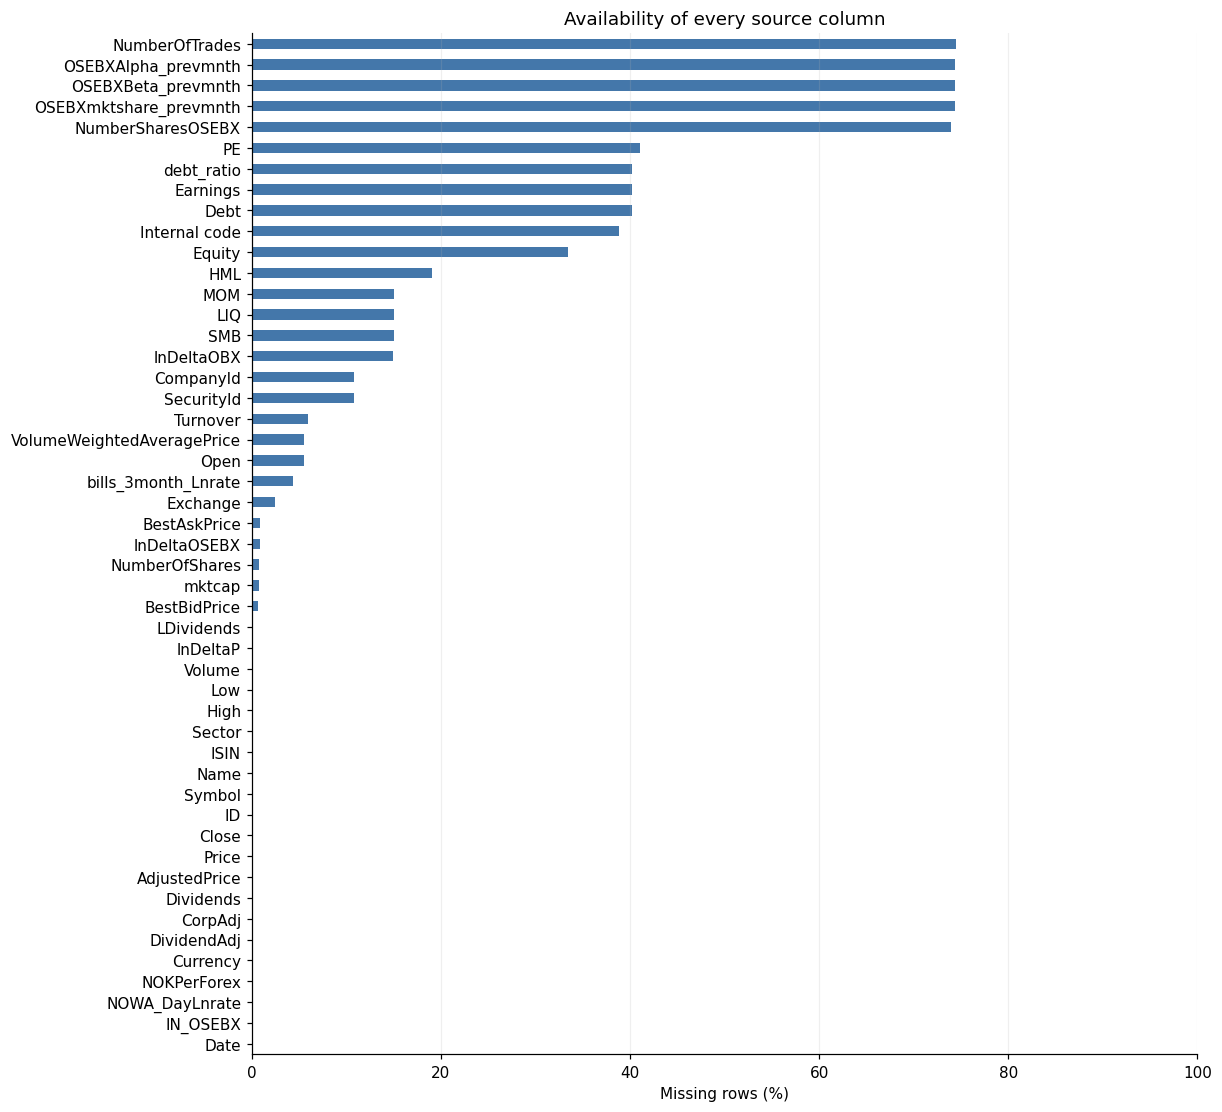

In [2]:
profile = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "available": data.notna().sum(),
    "missing": data.isna().sum(),
    "missing_%": data.isna().mean().mul(100),
    "distinct_nonmissing": data.nunique(),
})
display(profile.round(2))

fig, ax = plt.subplots(figsize=(11, 10), constrained_layout=True)
profile["missing_%"].sort_values().plot.barh(ax=ax, color="#4477AA")
ax.set(xlabel="Missing rows (%)", title="Availability of every source column", xlim=(0, 100))
ax.grid(axis="x", alpha=0.2)
plt.show()
plt.close(fig)

In [3]:
visualized_columns = []


def show_numeric(column: str) -> None:
    '''Summarize one numeric column and show its center and full-range percentiles.'''
    series = data[column]
    values = series.to_numpy(dtype=float)
    finite = values[np.isfinite(values)]
    summary = {
        "rows": len(series), "missing": int(series.isna().sum()),
        "nonfinite_not_missing": int((series.notna() & ~np.isfinite(values)).sum()),
        "zero": int((finite == 0).sum()), "negative": int((finite < 0).sum()),
    }
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
    if finite.size:
        probabilities = np.linspace(0, 1, 1001)
        quantiles = np.quantile(finite, probabilities)
        histogram_values = finite[finite != 0] if column in ("Dividends", "LDividends") else finite
        histogram_label = "Nonzero entries only" if column in ("Dividends", "LDividends") else "Finite entries"
        lo, hi = np.quantile(histogram_values, [0.01, 0.99])
        # For a dominant point mass (e.g. zero dividends), use the full range.
        if lo == hi:
            lo, hi = histogram_values.min(), histogram_values.max()
        central = histogram_values[(histogram_values >= lo) & (histogram_values <= hi)]
        axes[0].hist(central, bins=50 if lo != hi else 1, color="#4477AA")
        axes[0].set(xlabel="Stored value", ylabel="Rows",
                    title=f"{histogram_label}: window [{lo:.4g}, {hi:.4g}]\n"
                          f"{histogram_values.size - central.size:,} of these rows outside window")
        axes[1].plot(probabilities * 100, quantiles, color="#AA3377", linewidth=1.6)
        nonzero = np.abs(quantiles[quantiles != 0])
        threshold = max(float(np.median(nonzero)) * 0.01, 1e-12) if nonzero.size else 1
        axes[1].set_yscale("symlog", linthresh=threshold)
        axes[1].yaxis.get_major_locator().set_params(numticks=7)
        axes[1].set(xlabel="Percentile of finite rows", ylabel="Stored value (symlog)",
                    title="Full range: minimum through maximum", xlim=(0, 100))
        summary.update(dict(zip(
            ["min", "p01", "median", "p99", "max"],
            np.quantile(finite, [0, 0.01, 0.5, 0.99, 1]),
        )))
    else:
        for ax in axes:
            ax.text(0.5, 0.5, "No finite observations", ha="center", transform=ax.transAxes)
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.suptitle(column)
    display(pd.DataFrame([summary], index=[column]))
    plt.show()
    plt.close(fig)
    visualized_columns.append(column)


def show_category(column: str) -> None:
    '''Plot row counts for the most frequent labels without changing source values.'''
    series = data[column]
    if pd.api.types.is_numeric_dtype(series):
        labels = series.astype("Int64").astype("string")
    else:
        labels = series.astype("string").str.strip().replace("", pd.NA)
    counts = labels.fillna("<missing>").value_counts()
    top = counts.head(12).iloc[::-1]
    display(pd.DataFrame([{
        "rows": len(series), "missing_after_trimming": int(labels.isna().sum()),
        "distinct_raw": series.nunique(), "distinct_after_trimming": labels.nunique(),
    }], index=[column]))
    fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
    ax.barh(top.index.astype(str), top.values, color="#228833")
    ax.set(xlabel="Rows (not distinct companies)",
           title=f"{column}: top {len(top)} labels | {len(series) - int(top.sum()):,} rows in other labels")
    ax.grid(axis="x", alpha=0.2)
    plt.show()
    plt.close(fig)
    visualized_columns.append(column)

## 3. Column-by-column guide

### 01. `Date` — observation date

Parsed as a calendar date using the CSV's `YYYY-MM-DD` format. It identifies when a
row is recorded, with no intraday timestamp. The file's export timestamp is not an
observation date. The chart shows how panel coverage changes through time; more rows
can reflect more listed securities rather than greater trading activity. Calendar gaps
are retained as zero-record days in the coverage chart, not filled with price data.

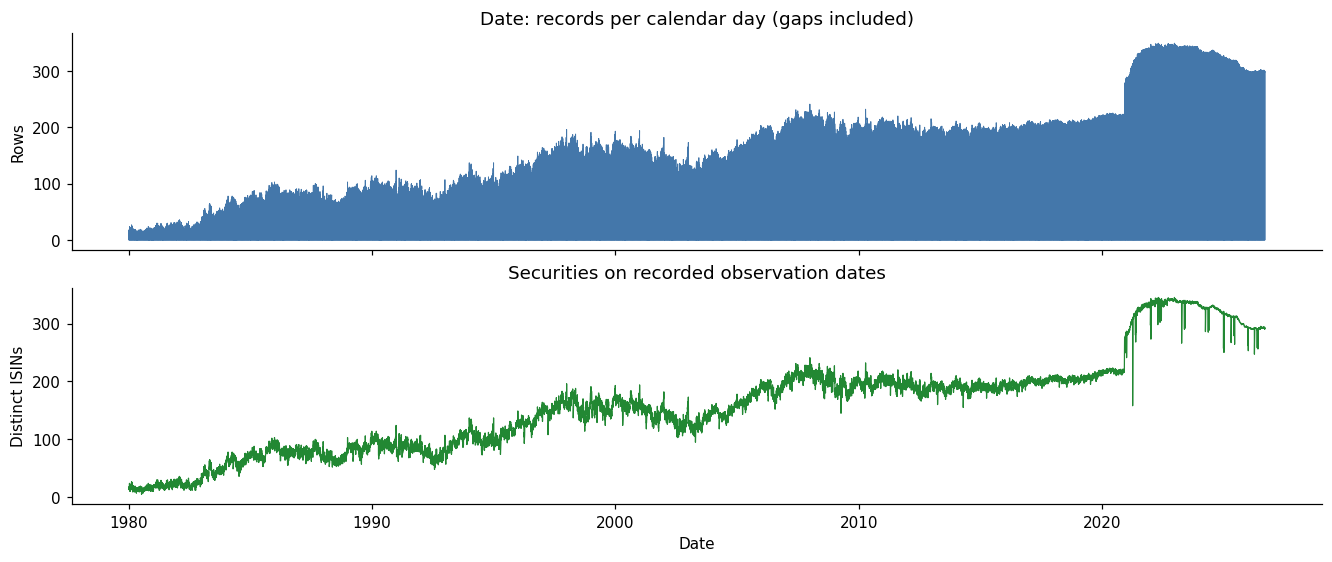

In [4]:
daily_rows = data.groupby("Date").size().sort_index()
daily_rows = daily_rows.reindex(pd.date_range(daily_rows.index.min(), daily_rows.index.max()), fill_value=0)
daily_isins = data.groupby("Date")["ISIN"].nunique().sort_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, constrained_layout=True)
axes[0].plot(daily_rows.index, daily_rows.values, linewidth=0.6, color="#4477AA")
axes[0].set(ylabel="Rows", title="Date: records per calendar day (gaps included)")
axes[1].plot(daily_isins.index, daily_isins.values, linewidth=0.8, color="#228833")
axes[1].set(xlabel="Date", ylabel="Distinct ISINs", title="Securities on recorded observation dates")
plt.show()
plt.close(fig)
visualized_columns.append("Date")

### 02. `Internal code` — Provider's internal code

A numeric-looking identifier. Its precise scope and stability are not documented in the CSV. Missing codes are shown rather than inferred; arithmetic on these labels has no financial meaning.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
Internal code,1876617,727990,419,419


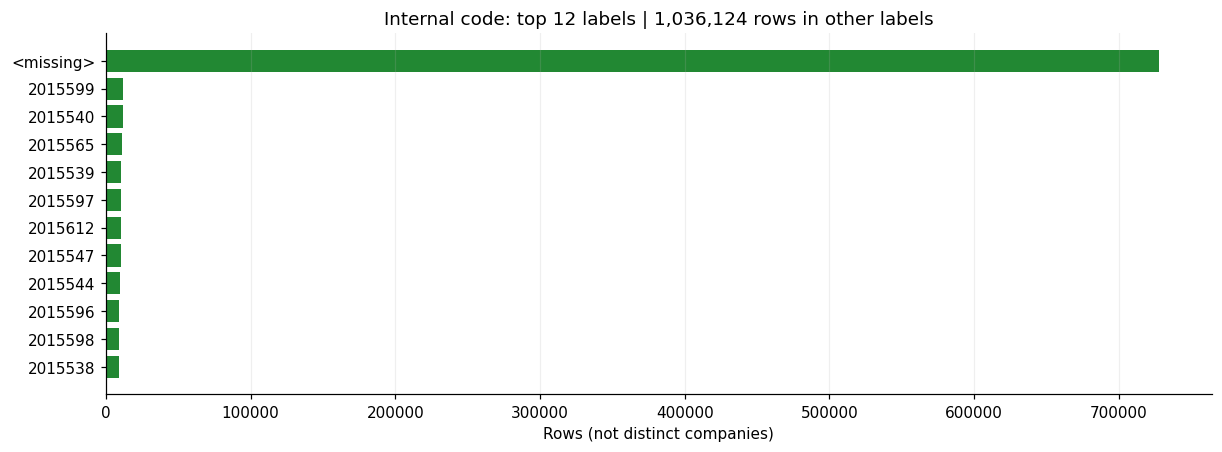

In [5]:
show_category('Internal code')

### 03. `SecurityId` — Security-level identifier

Interpreted from the name as a provider identifier for a security. Do not assume it is present on every row or that `(SecurityId, Date)` is unique. Different share classes can belong to one company; identifier coverage and duplicate keys are checked below.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
SecurityId,1876617,203065,868,868


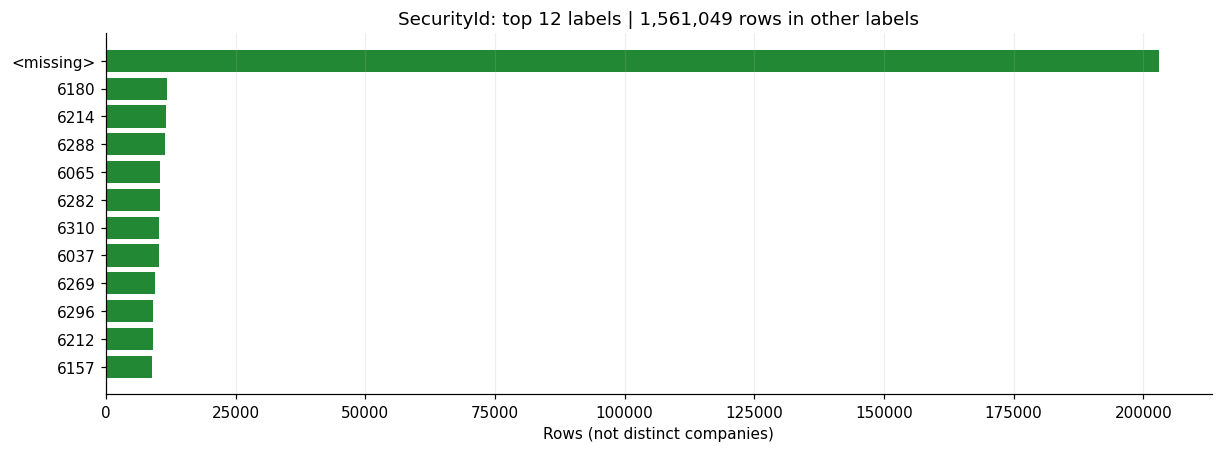

In [6]:
show_category('SecurityId')

### 04. `CompanyId` — Company-level identifier

Interpreted as a provider identifier for the issuing company. A company can have multiple securities and changing names. Missing values remain missing: this notebook does not borrow identifier repairs from other notebooks.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
CompanyId,1876617,203168,740,740


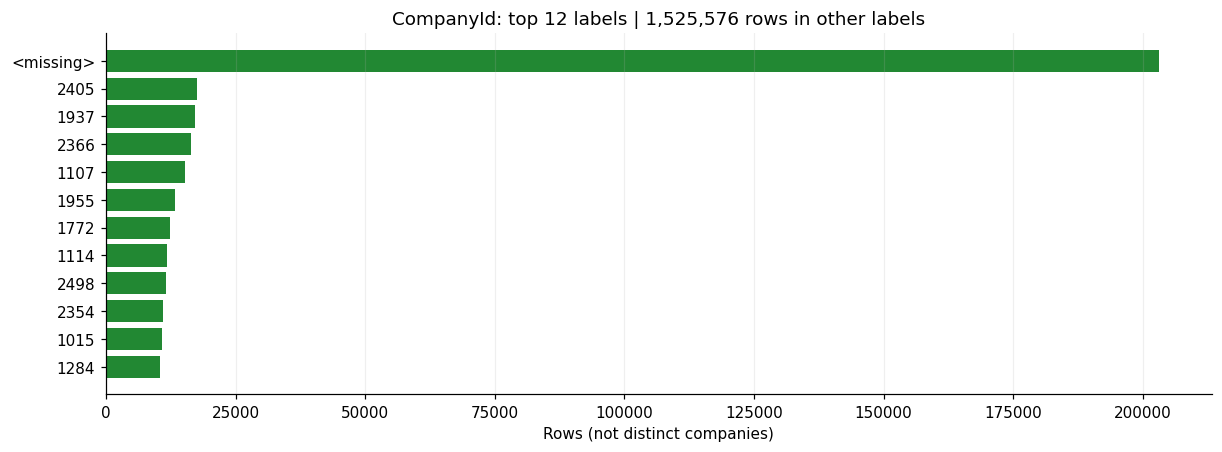

In [7]:
show_category('CompanyId')

### 05. `Symbol` — Trading symbol

A text label such as `2020`, even when it looks numeric. Symbols can change or be reused, so they should not automatically serve as permanent company identifiers.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
Symbol,1876617,0,1145,1145


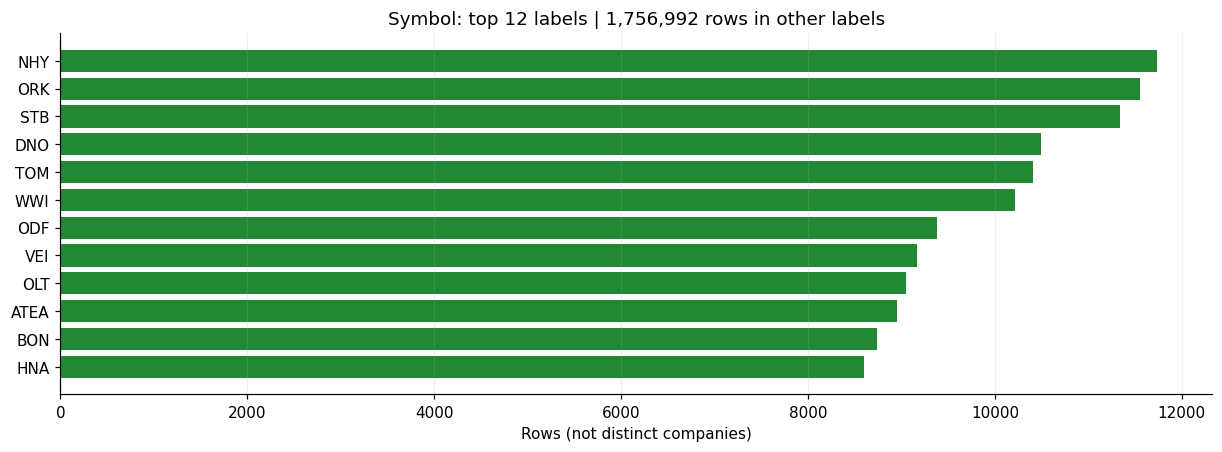

In [8]:
show_category('Symbol')

### 06. `ISIN` — Security identifier

Conventionally the International Securities Identification Number, identifying a security rather than necessarily an entire company. The file contains many ISINs. Changes in a company's ISIN can split its history; no histories are stitched together here.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
ISIN,1876617,0,1133,1133


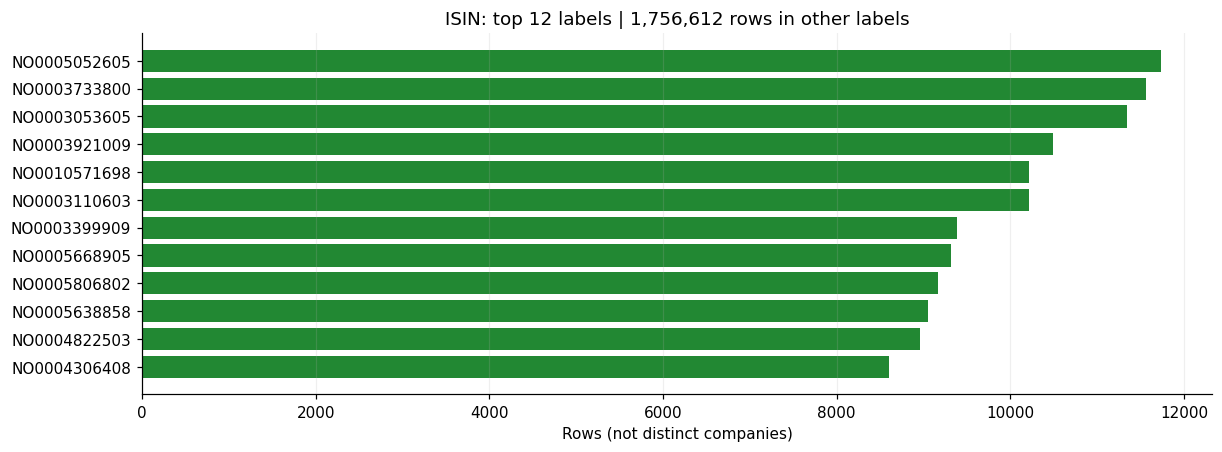

In [9]:
show_category('ISIN')

### 07. `Name` — Recorded security/company name

A descriptive label, not a stable key. The file contains spelling/case variants and trailing spaces. The chart trims whitespace only; it does not merge name changes or case variants into companies.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
Name,1876617,0,1582,1444


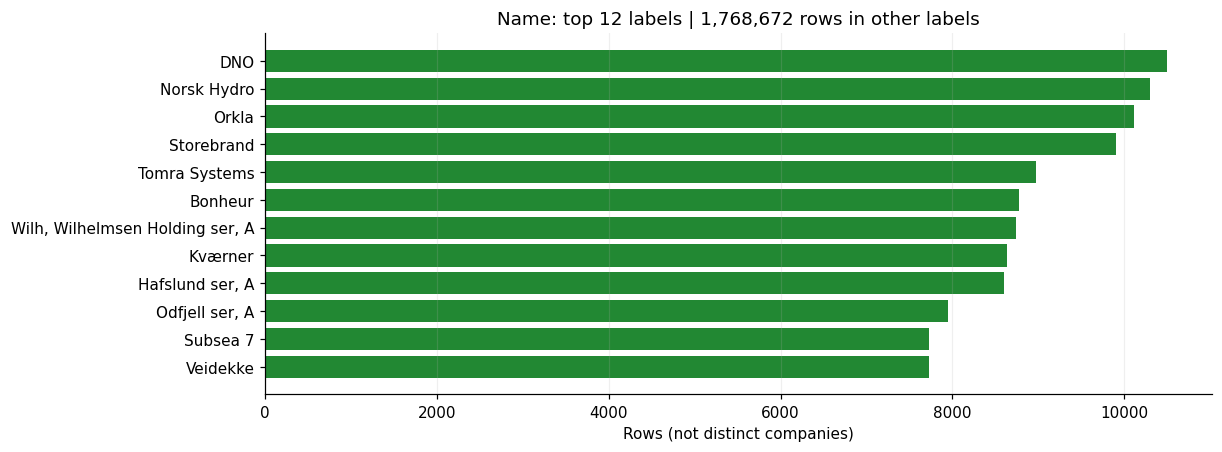

In [10]:
show_category('Name')

### 08. `BestBidPrice` — Best bid quote

Conventionally the highest quoted buying price, in the recorded currency per share. The CSV does not specify the quote observation time. Negative values such as `-999999999` occur and look like placeholder codes, not economically valid bid prices; they remain visible and are counted below.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
BestBidPrice,1876617,11697,0,8331,1207,-999999999.0,0.15,37.0,560.0,24000.0


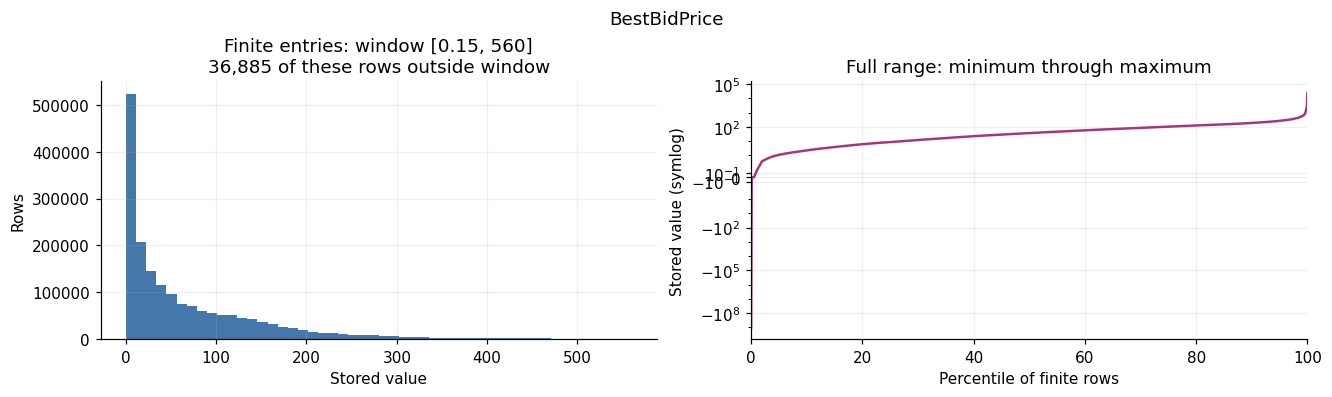

In [11]:
show_numeric('BestBidPrice')

### 09. `BestAskPrice` — Best ask quote

Conventionally the lowest quoted selling price, in the recorded currency per share. Quote timing and validity rules are undocumented. As with bids, negative placeholder-like values are retained. Bid and ask should both be checked before calculating a spread.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
BestAskPrice,1876617,16892,0,4979,695,-999999999.0,0.24,38.0,570.0,25000.0


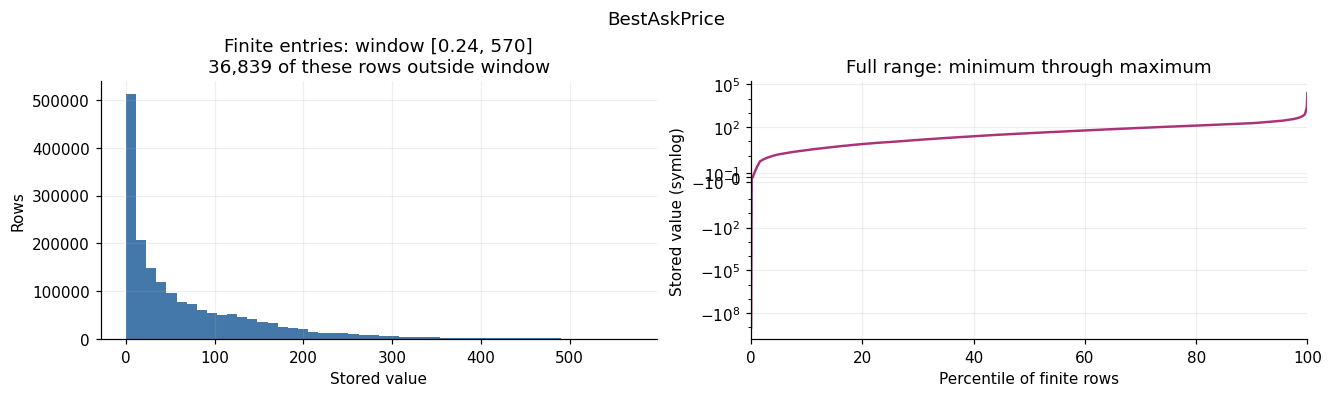

In [12]:
show_numeric('BestAskPrice')

### 10. `Open` — Opening price

Conventionally the session opening price, in the recorded currency per share. The provider's auction/session convention is not available. Both missing and zero values exist; zero should not silently be interpreted as a valid traded price.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Open,1876617,103597,0,26269,0,0.0,0.0,33.0,494.481,17500.0


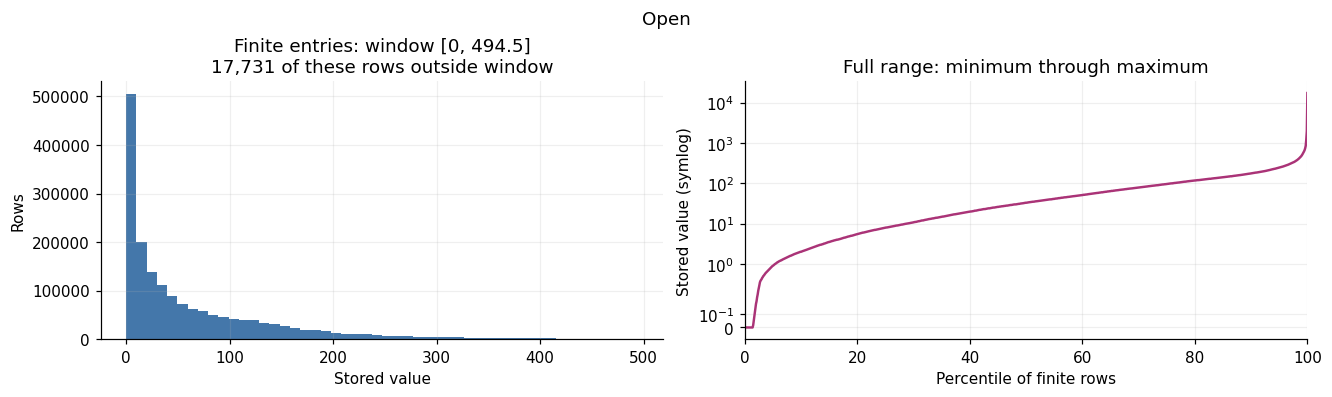

In [13]:
show_numeric('Open')

### 11. `High` — Session high price

Conventionally the highest traded price during the recorded session, in currency per share. Zero and missing entries need attention before calculating price ranges. The consistency check below compares the high with the low on rows with positive values.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
High,1876617,9,0,26269,0,0.0,0.0,37.7,570.5,25000.0


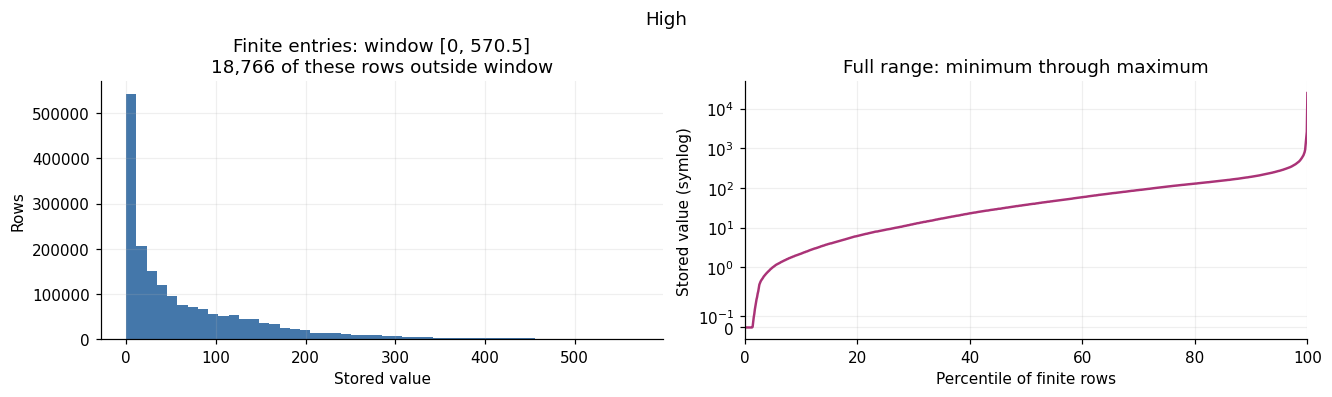

In [14]:
show_numeric('High')

### 12. `Low` — Session low price

Conventionally the lowest traded price during the session, in currency per share. This is distinct from the bid quote. Zeros are retained and reported rather than replaced.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Low,1876617,9,0,26269,0,0.0,0.0,36.5,560.0,25000.0


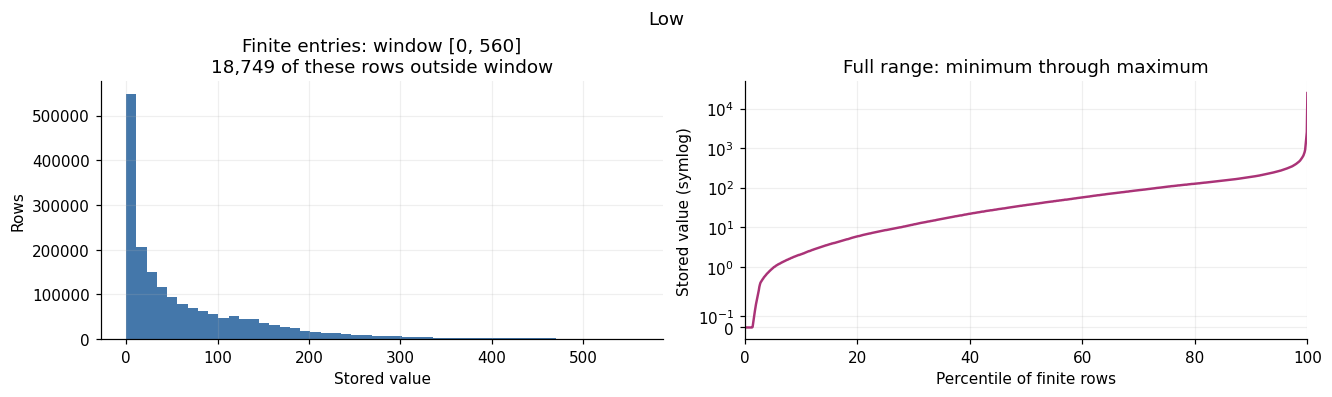

In [15]:
show_numeric('Low')

### 13. `Close` — Closing price

Conventionally the recorded session closing price, in currency per share. This field has zero observations in the file and should not automatically be treated as identical to `Price`; their agreement is measured below.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Close,1876617,0,0,26269,0,0.0,0.0,37.0,566.0,25000.0


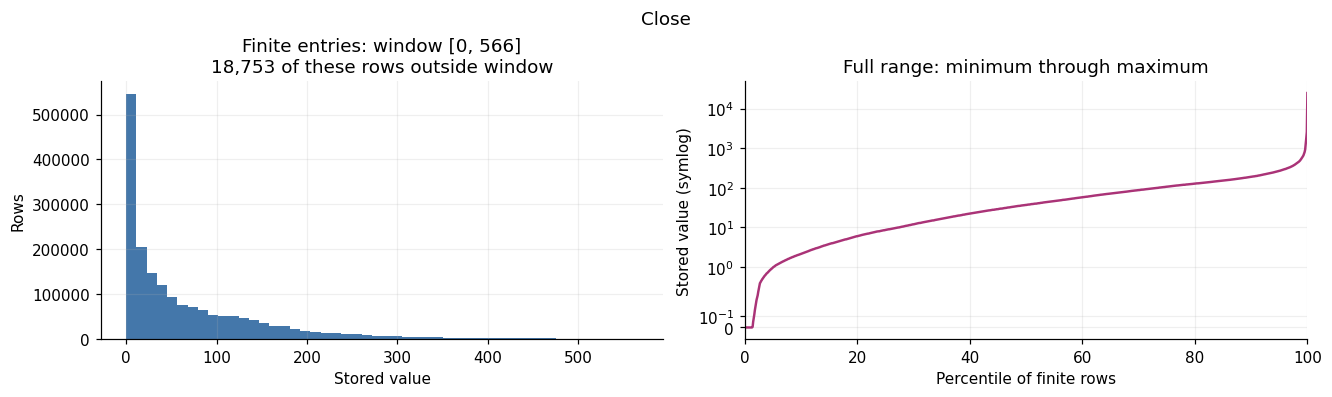

In [16]:
show_numeric('Close')

### 14. `NumberOfTrades` — Recorded trade count

Interpreted as the number of trades in the observation period, in trades. A missing count is not evidence that no trading occurred. This column has substantial missing coverage, which the overview quantifies.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
NumberOfTrades,1876617,1396957,0,26269,0,0.0,0.0,66.0,4661.41,103757.0


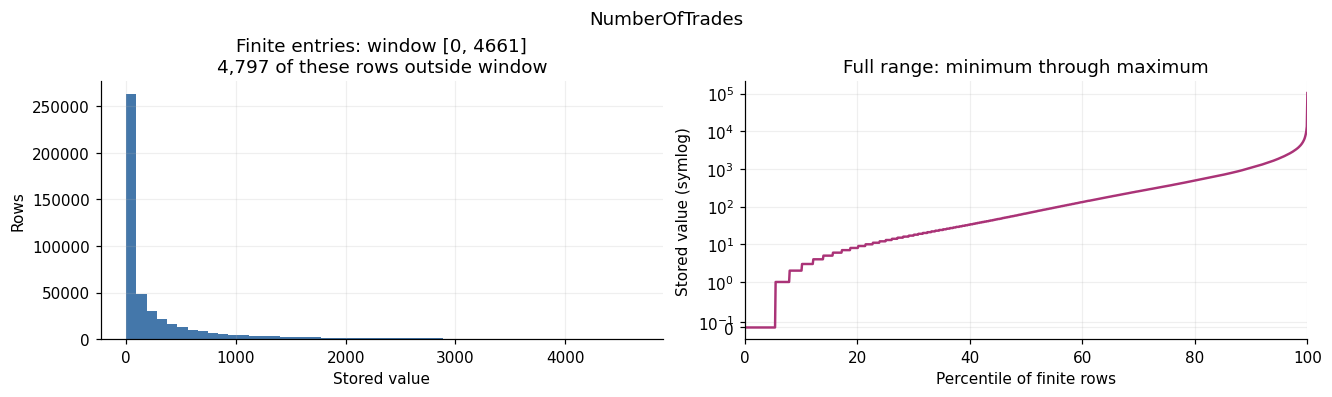

In [17]:
show_numeric('NumberOfTrades')

### 15. `Volume` — Recorded trading volume

Conventionally the number of shares or units traded in the period. Negative observations occur in this file; the CSV alone cannot establish whether these are errors or special records. They are retained. Long histories and stock splits make pooled levels difficult to compare economically.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Volume,1876617,71,0,26269,5,-1.819466e+09,0.0,29000.0,10557019.2,1.976764e+09


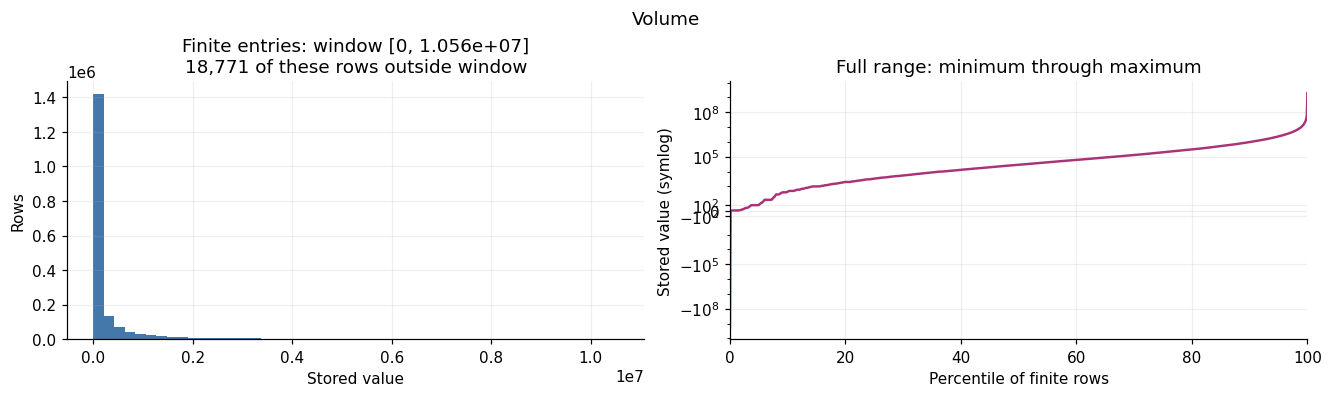

In [18]:
show_numeric('Volume')

### 16. `Turnover` — Recorded traded value

Conventionally the monetary value traded during the period. A candidate relationship is `Volume × VolumeWeightedAveragePrice`; agreement is checked below to assess compatibility with the quoted price/volume units. Do not confuse this with the accounting meaning of turnover (sales revenue).

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Turnover,1876617,110834,0,19033,0,0.0,0.0,757250.0,3.494495e+08,1.632357e+10


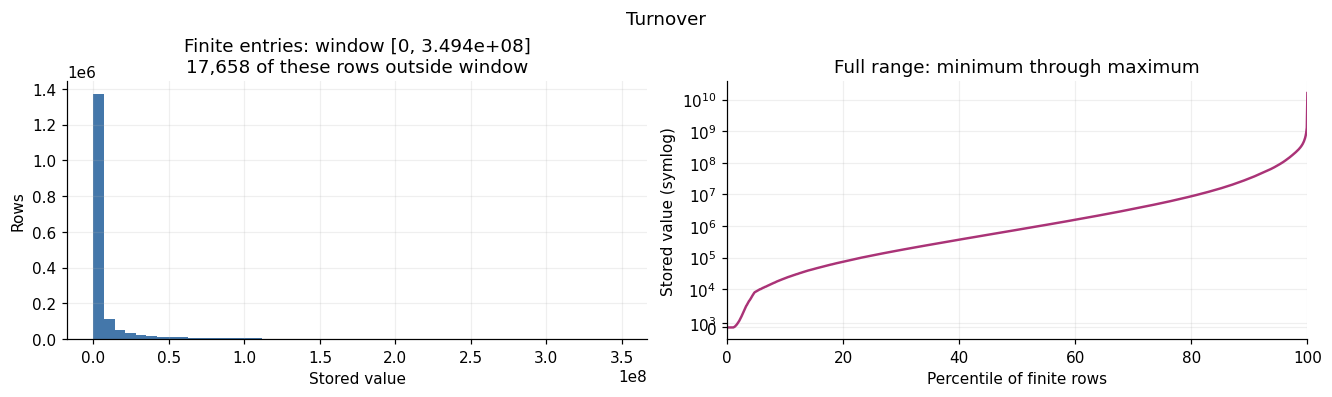

In [19]:
show_numeric('Turnover')

### 17. `VolumeWeightedAveragePrice` — Volume-weighted average price (VWAP)

Conventionally the sum of trade price times trade size divided by total trade size, in currency per share. It can differ from both the closing price and an unweighted average price. Negative values exist and need investigation; they are not removed here.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
VolumeWeightedAveragePrice,1876617,103714,0,0,5,-0.554673,0.286048,34.154903,500.643004,17500.0


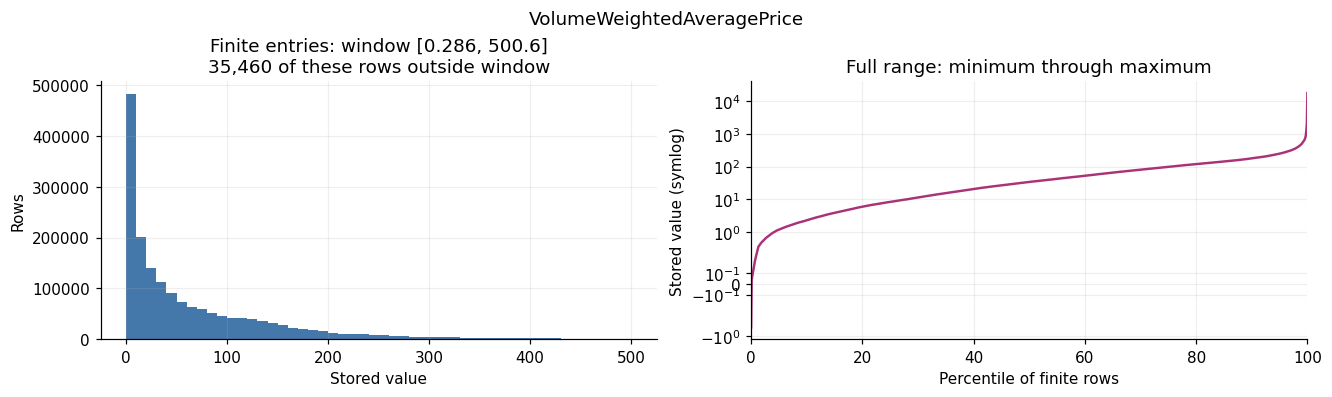

In [20]:
show_numeric('VolumeWeightedAveragePrice')

### 18. `Price` — Provider price series

A recorded price field that may use provider-specific selection or carry-forward rules. The CSV does not identify those rules, so this is not assumed to be exactly the closing trade price. `Price` and `Close` are compared below; the adjustment identity also uses this field.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Price,1876617,0,0,0,0,0.0001,0.3,38.2,570.0,25000.0


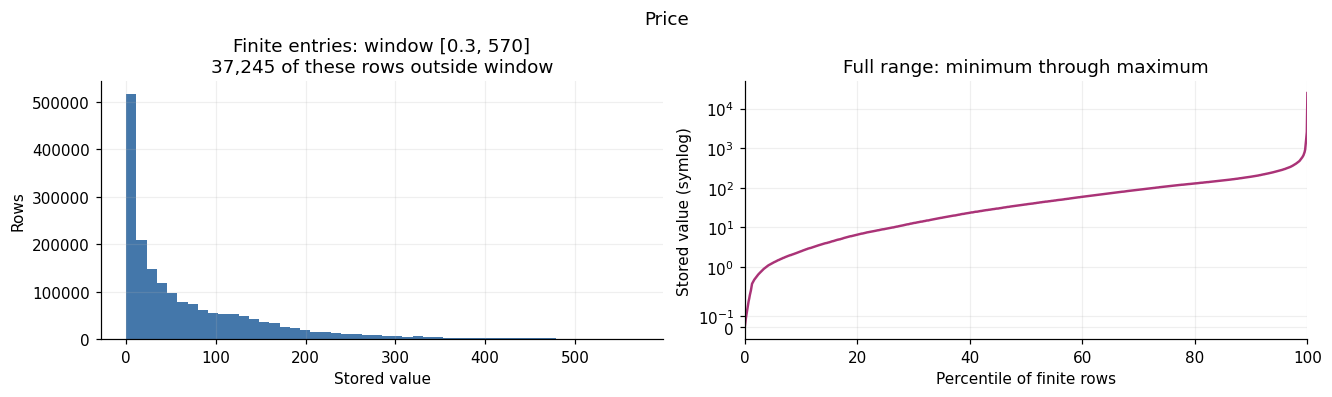

In [21]:
show_numeric('Price')

### 19. `AdjustedPrice` — Adjusted price series

An adjusted price level on a different historical scale from `Price`. The candidate identity `AdjustedPrice = Price × CorpAdj × DividendAdj` is tested below. Adjustment normalization and the treatment of corporate actions are not documented; the level is not an executable quote or itself a return.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
AdjustedPrice,1876617,0,0,0,0,0.000044,0.19,26.254356,15282.505295,4.529261e+07


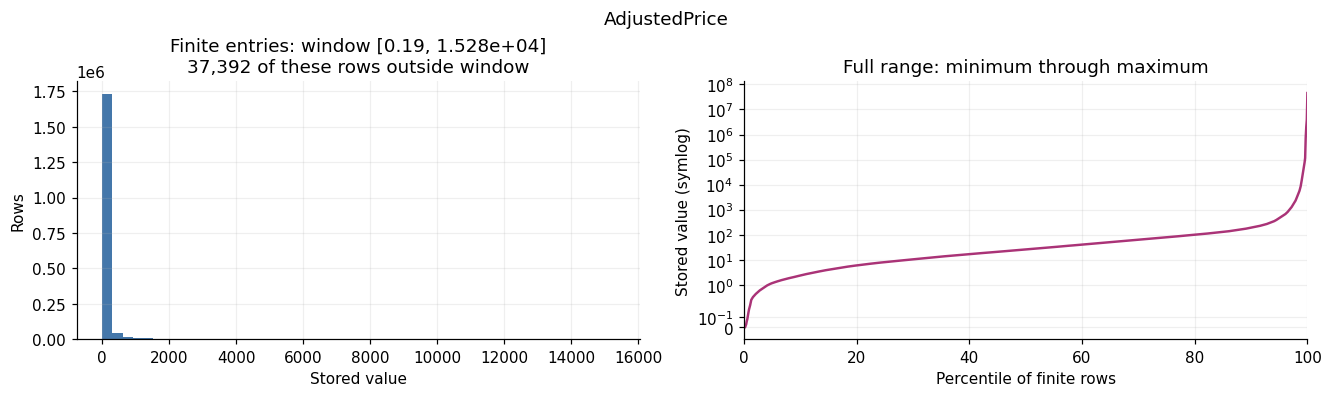

In [22]:
show_numeric('AdjustedPrice')

### 20. `Dividends` — Dividend-related amount

Interpreted from its name as a dividend amount recorded on a row. Zero dominates the distribution. The CSV does not establish the payment/ex-dividend timing, currency basis, or whether all entries represent ordinary cash dividends. Do not add this mechanically to a return series that may already include dividend effects.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Dividends,1876617,0,0,1871642,0,0.0,0.0,0.0,0.0,869.384


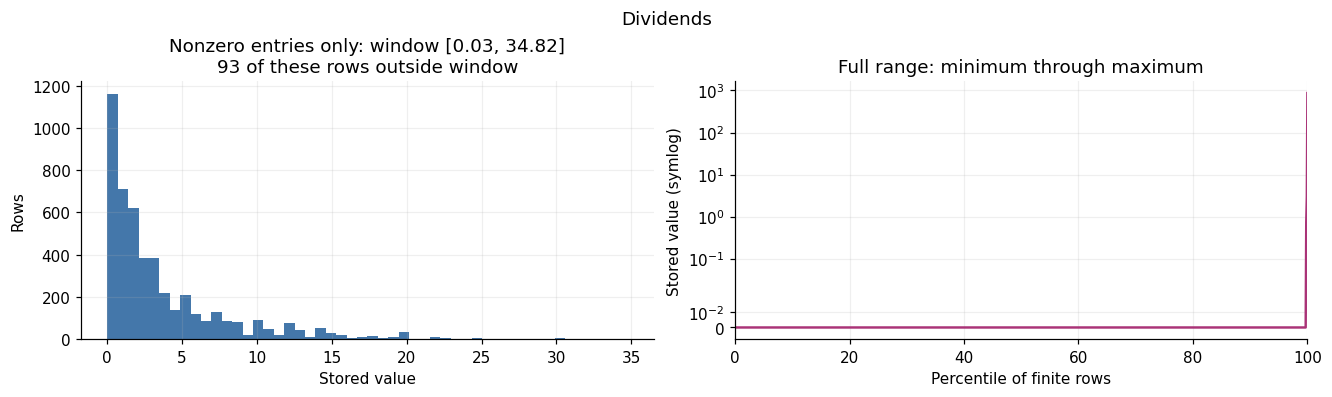

In [23]:
show_numeric('Dividends')

### 21. `LDividends` — Second dividend-related field

The `L` prefix is not defined in the CSV. It could reflect a provider convention, but neither a lag interpretation nor a local-currency interpretation is assumed. Its missingness and agreement with `Dividends` are measured below; agreement would not prove its intended definition.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
LDividends,1876617,1140,0,1870503,0,0.0,0.0,0.0,0.0,869.384


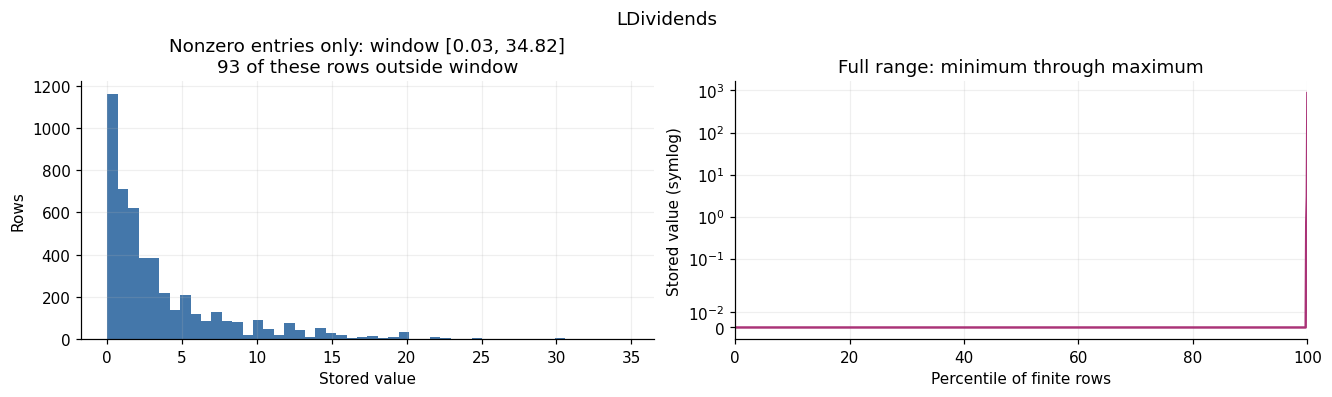

In [24]:
show_numeric('LDividends')

### 22. `CorpAdj` — Corporate-action adjustment factor (inferred)

Interpreted as a multiplicative corporate-action adjustment from the name and the candidate adjusted-price identity. It is dimensionless in that interpretation. It is not a count of splits, and its normalization cannot be inferred simply from being above or below one.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
CorpAdj,1876617,0,0,0,0,0.001199,0.03383,1.0,1816.594142,1.695150e+06


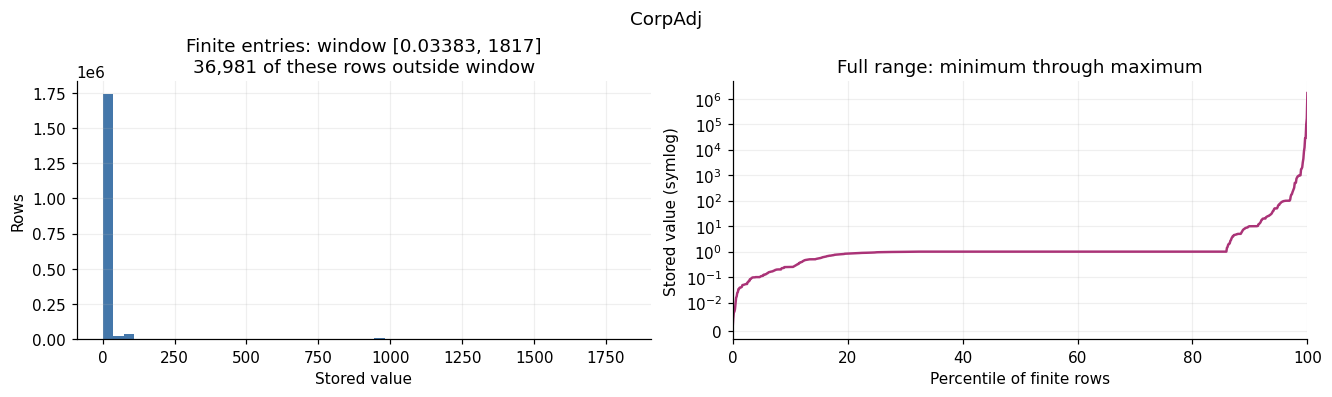

In [25]:
show_numeric('CorpAdj')

### 23. `DividendAdj` — Dividend adjustment factor (inferred)

Interpreted as a dimensionless multiplicative dividend adjustment, tested jointly with `CorpAdj` below. It is distinct from a cash dividend amount. Its exact reinvestment, timing, and normalization conventions remain unverified.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
DividendAdj,1876617,0,0,0,0,0.002153,0.039777,0.913632,1.0,1.0


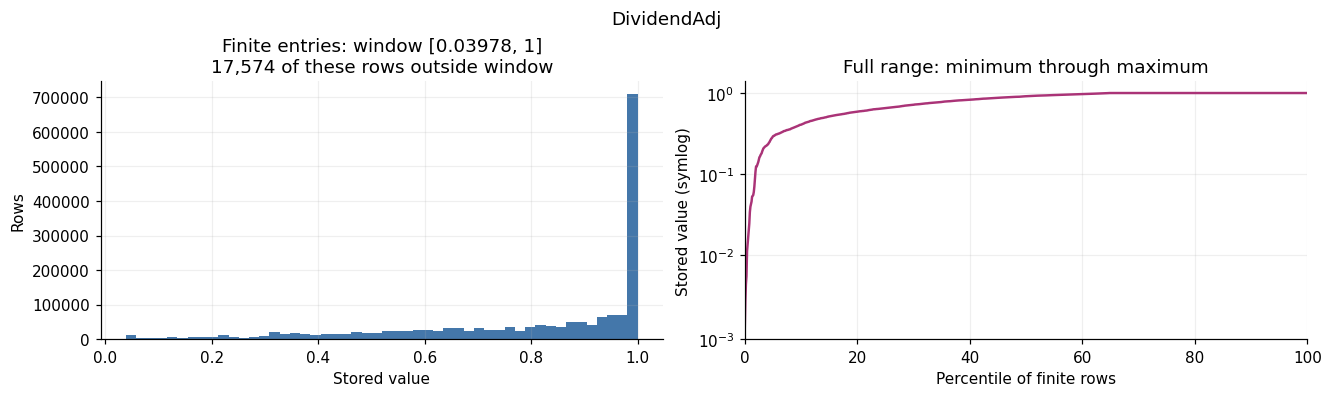

In [26]:
show_numeric('DividendAdj')

### 24. `Currency` — Recorded currency code

The actual labels show the currency basis supplied in the file. All rows in this export are labelled `NOK`. A constant column carries metadata even though it has no cross-sectional variation; this does not establish the accounting currency of `Equity`, `Debt`, or `Earnings`.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
Currency,1876617,0,1,1


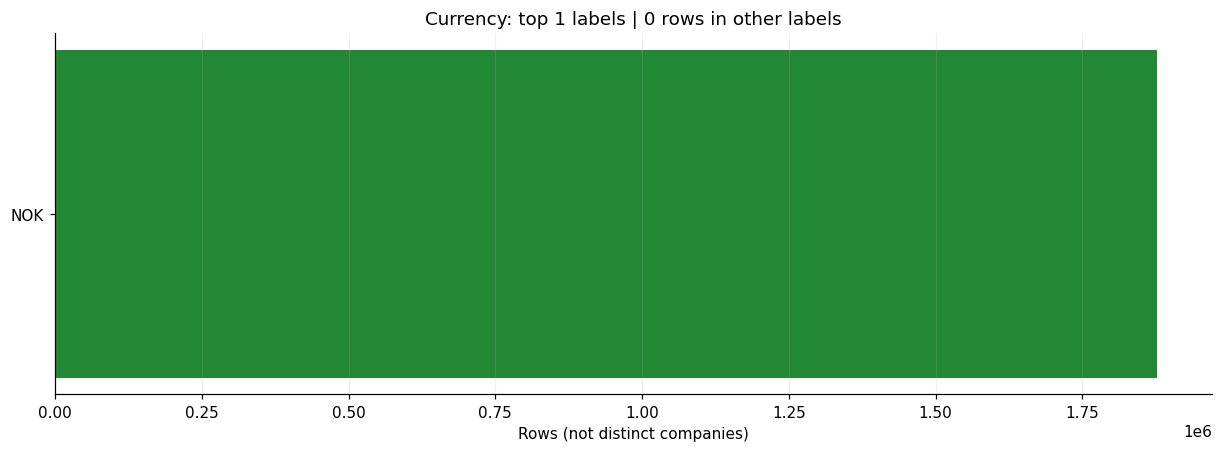

In [27]:
show_category('Currency')

### 25. `NumberOfShares` — Recorded share count

Interpreted as shares outstanding for the recorded security, in shares. Share-class treatment and effective-date rules are not documented. Missing and zero values are retained. Its candidate link to `mktcap` is tested below.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
NumberOfShares,1876617,13973,0,858,0,0.0,492825.0,48334673.0,2.068998e+09,4.777241e+10


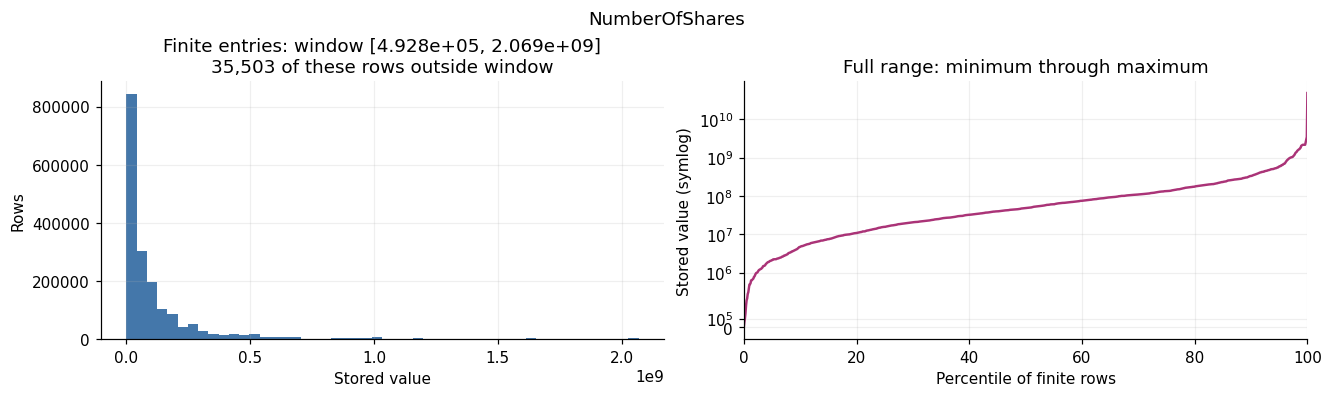

In [28]:
show_numeric('NumberOfShares')

### 26. `NumberSharesOSEBX` — OSEBX-related share count

The name suggests a share count used in an OSEBX index context. Whether this is free-float adjusted, capped, or based on another index convention is not established by the file. It should not automatically replace `NumberOfShares` in market-cap calculations.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
NumberSharesOSEBX,1876617,1387135,0,0,0,1368576.0,4859219.0,78296820.0,1.457297e+09,2.810949e+09


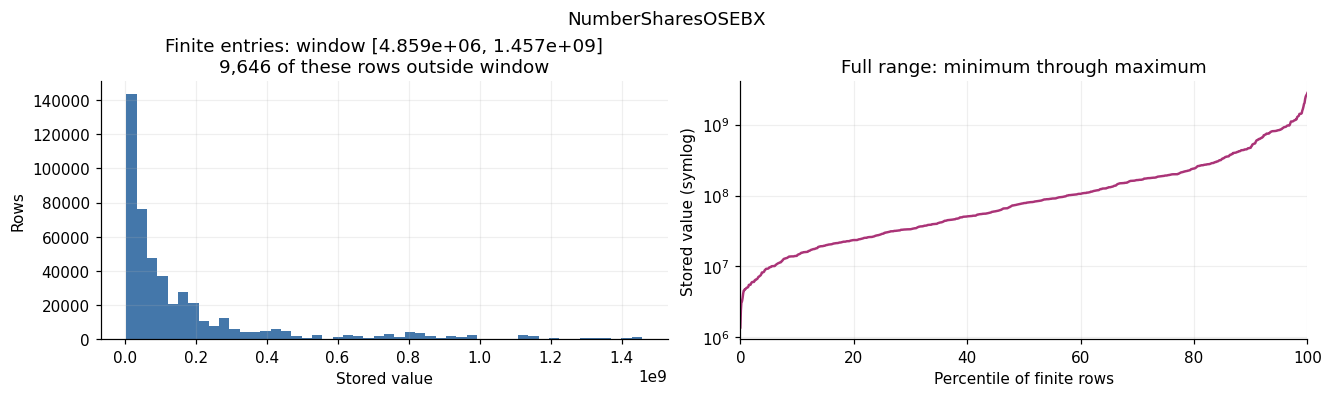

In [29]:
show_numeric('NumberSharesOSEBX')

### 27. `Exchange` — Recorded venue code

A categorical exchange/venue label. Several codes occur, along with missing values. The CSV does not provide a codebook, so codes are displayed as supplied rather than mapped to present-day venues or interpreted as simultaneous cross-listings.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
Exchange,1876617,46287,5,5


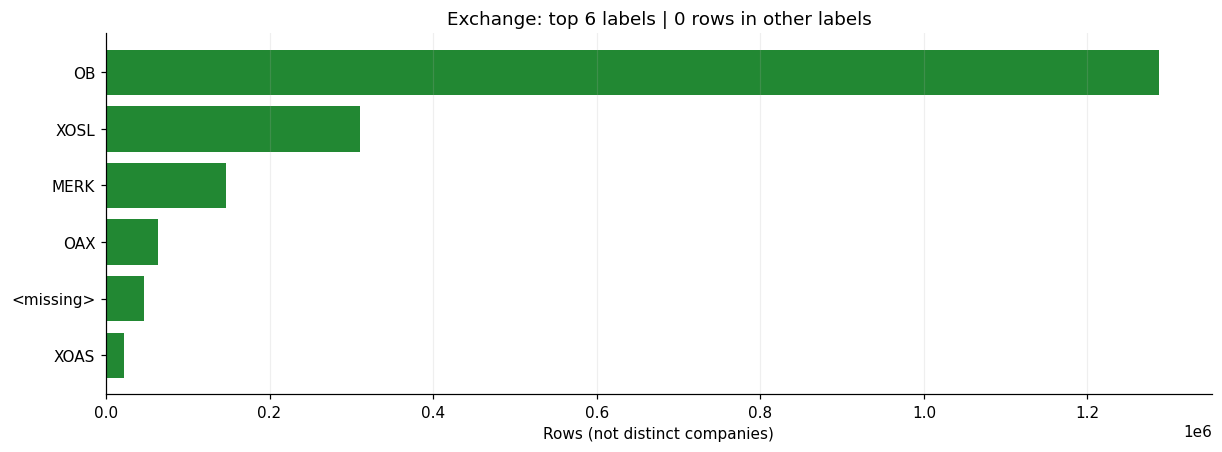

In [30]:
show_category('Exchange')

### 28. `NOKPerForex` — NOK conversion factor (inferred)

Interpreted from the name as NOK per unit of a source currency. It equals one throughout this export, consistent with the constant `NOK` currency label. These observations cannot validate the factor's behavior for other currencies or its application to accounting fields.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
NOKPerForex,1876617,0,0,0,0,1.0,1.0,1.0,1.0,1.0


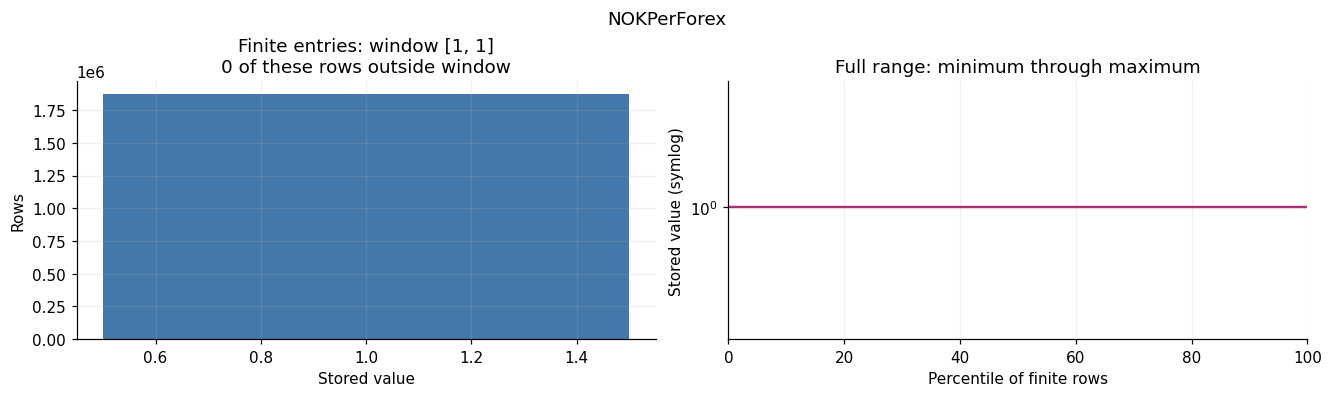

In [31]:
show_numeric('NOKPerForex')

### 29. `mktcap` — Recorded market capitalization

Conventionally the market value of outstanding shares, here tested against `Price × NumberOfShares × NOKPerForex`. Agreement would support a NOK value on the supplied share-count basis. It would not resolve share-class aggregation, so summing company records can double-count economic exposures.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
mktcap,1876617,13973,0,858,0,0.0,25467612.84,1.142400e+09,1.308051e+11,1.289717e+12


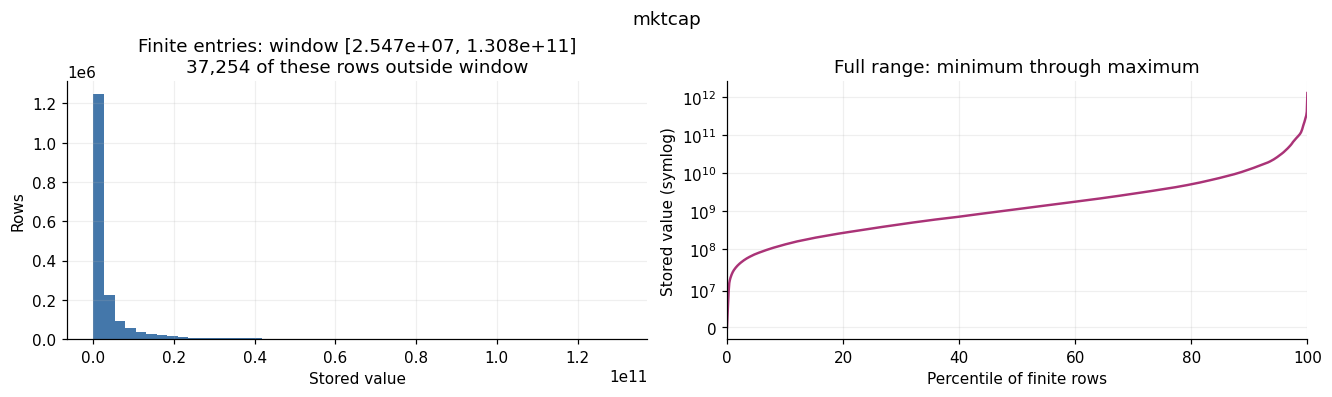

In [32]:
show_numeric('mktcap')

### 30. `OSEBXmktshare_prevmnth` — Previous-month OSEBX market share/weight (inferred)

The name suggests a lagged market-share or index-weight field. Values look like fractions, not percentage points, but the exact denominator and reference date are unverified. This field is not assumed to equal current market cap divided by a total calculated from this export.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
OSEBXmktshare_prevmnth,1876617,1395222,0,0,0,0.000003,0.000135,0.00416,0.127718,0.293921


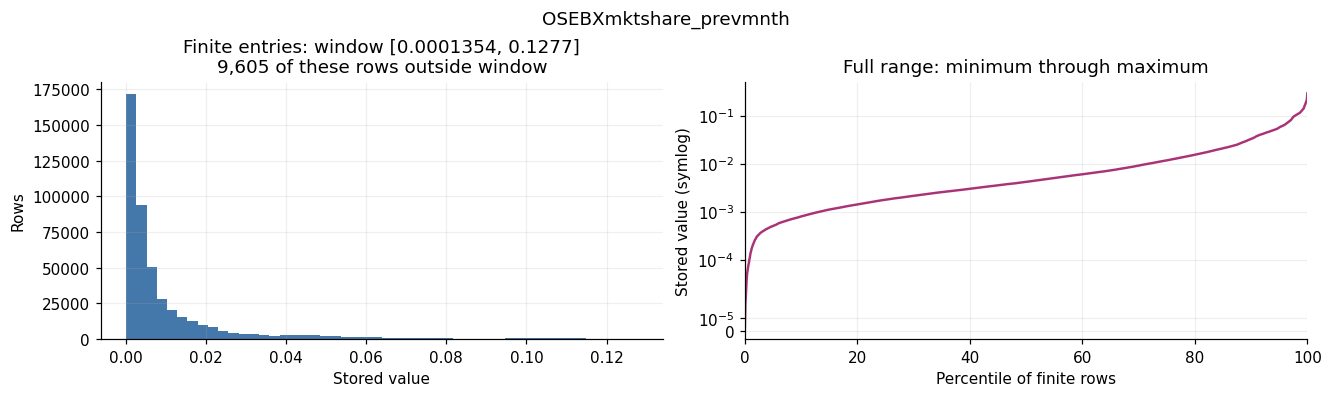

In [33]:
show_numeric('OSEBXmktshare_prevmnth')

### 31. `OSEBXAlpha_prevmnth` — Previous-month OSEBX alpha estimate (inferred)

Conventionally alpha is an intercept in a return regression. The name suggests an estimate recorded for the previous month, but estimation window, return basis, frequency, and risk-free adjustment are unknown. Values are shown in stored units without annualization or a causal interpretation.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
OSEBXAlpha_prevmnth,1876617,1395287,0,23,254063,-0.22452,-0.02301,-0.000273,0.015861,0.752163


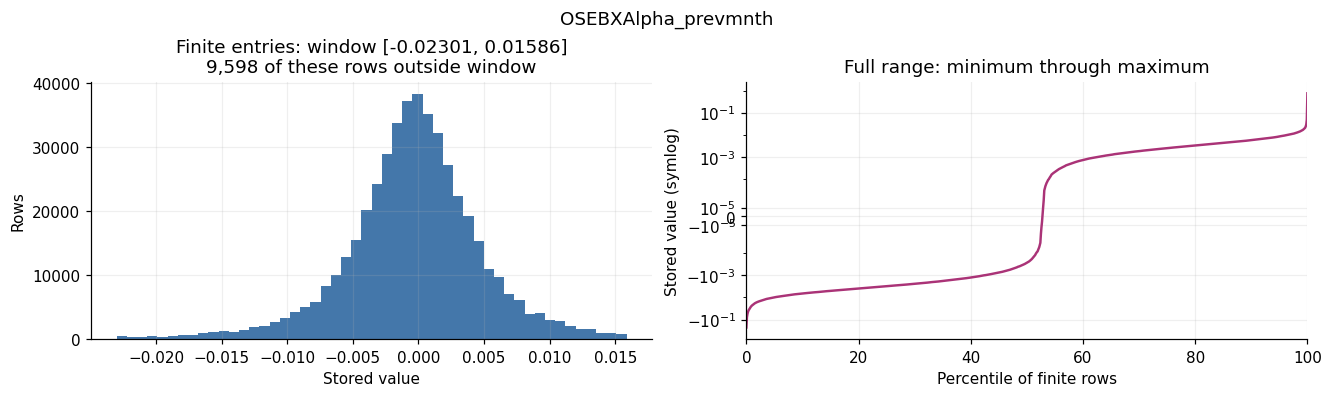

In [34]:
show_numeric('OSEBXAlpha_prevmnth')

### 32. `OSEBXBeta_prevmnth` — Previous-month OSEBX beta estimate (inferred)

Conventionally beta measures sensitivity to a benchmark return and is dimensionless when both returns use the same units. The precise regression/window is unverified. Large and negative estimates remain visible; they are not evidence of a reliable hedge by themselves.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
OSEBXBeta_prevmnth,1876617,1395287,0,0,52798,-38.377345,-1.231584,0.810548,3.558108,23.073154


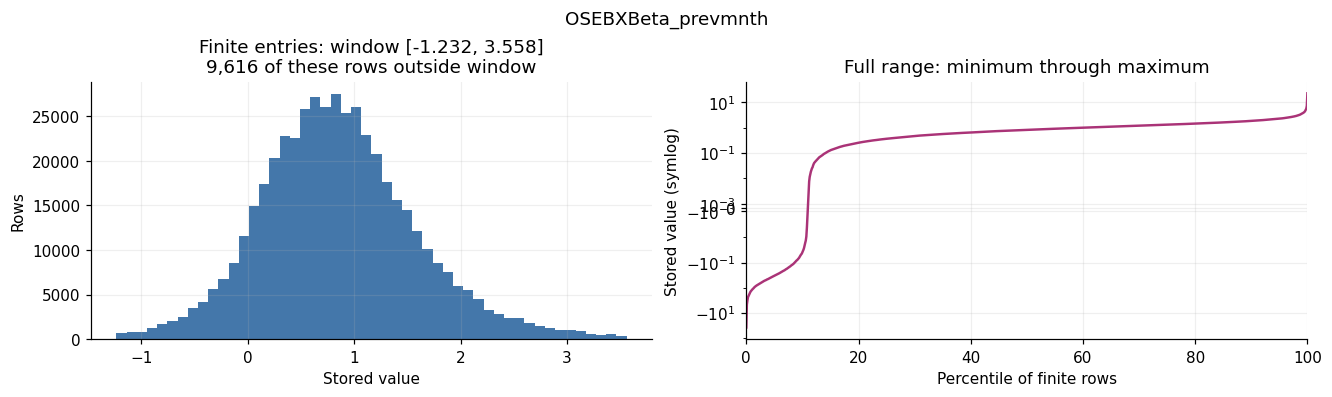

In [35]:
show_numeric('OSEBXBeta_prevmnth')

### 33. `SMB` — Size factor (conventional interpretation)

SMB conventionally means small minus big: a return spread between portfolios of smaller and larger companies. The CSV does not identify its portfolio universe, weighting, rebalance rule, or return convention. It is displayed in stored units; the name alone cannot verify factor construction.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
SMB,1876617,282042,0,295,795465,-0.071481,-0.02557,0.000031,0.026455,0.082751


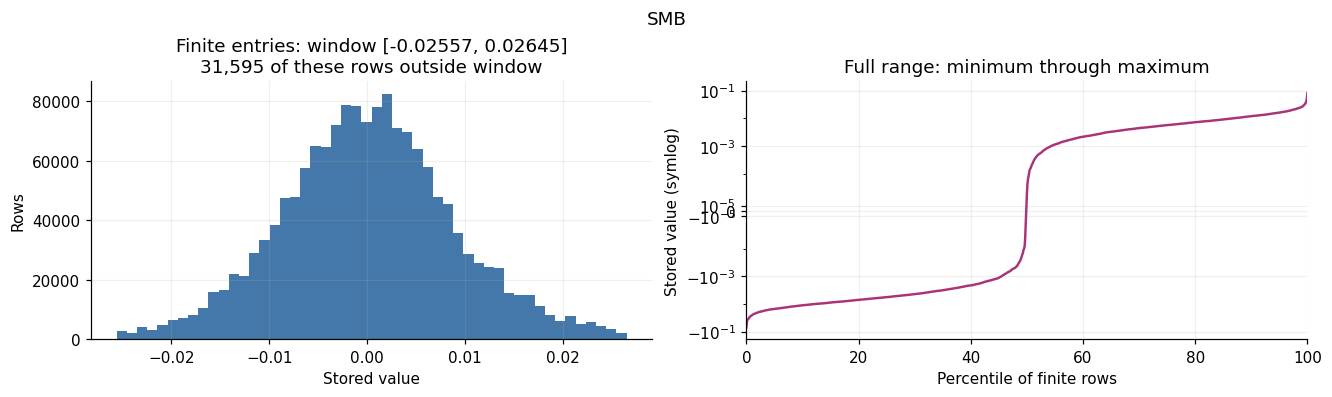

In [36]:
show_numeric('SMB')

### 34. `HML` — Value factor (conventional interpretation)

HML conventionally means high minus low, usually referring to a book-to-market portfolio spread. Exact sorts and construction are not supplied. This is a factor-like return series, not an individual company's book-to-market ratio.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
HML,1876617,358178,0,586,746484,-0.159866,-0.036021,0.000205,0.039214,0.121377


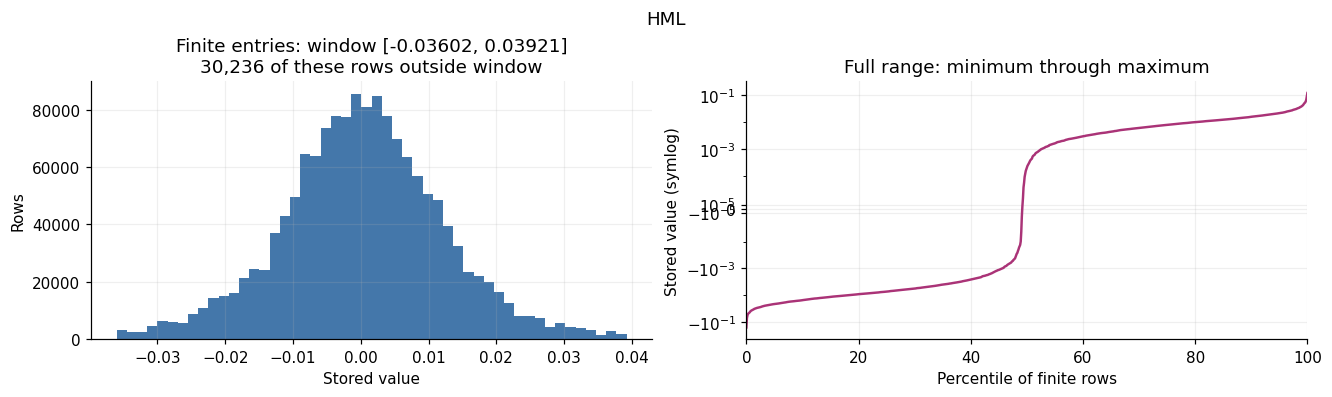

In [37]:
show_numeric('HML')

### 35. `LIQ` — Liquidity-related factor (inferred)

The name suggests a liquidity factor or return spread. Its sign convention, liquidity measure, and portfolio construction are not defined in the file. A positive value therefore cannot be translated confidently into 'more liquid stocks outperformed' without a codebook.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
LIQ,1876617,282042,0,0,798658,-0.103228,-0.028865,-0.000014,0.025799,0.125714


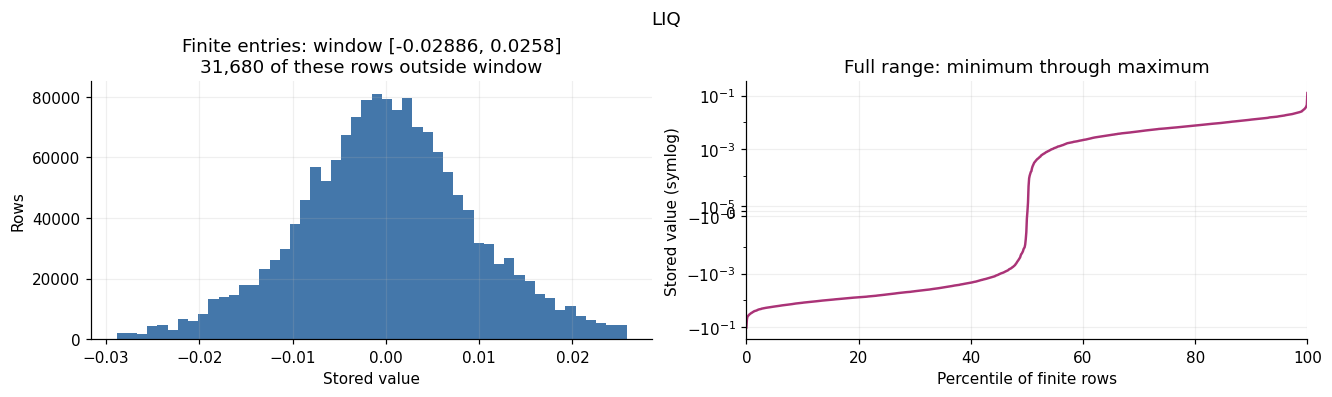

In [38]:
show_numeric('LIQ')

### 36. `MOM` — Momentum factor (conventional interpretation)

Conventionally a return spread associated with past winners versus past losers. Lookback, skipped periods, weighting, and long/short sign conventions are not documented. The cross-row histogram can overweight dates with more listed securities; the date-consistency table below helps assess repetition.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
MOM,1876617,282042,0,295,753426,-0.097701,-0.035873,0.000651,0.034227,0.083916


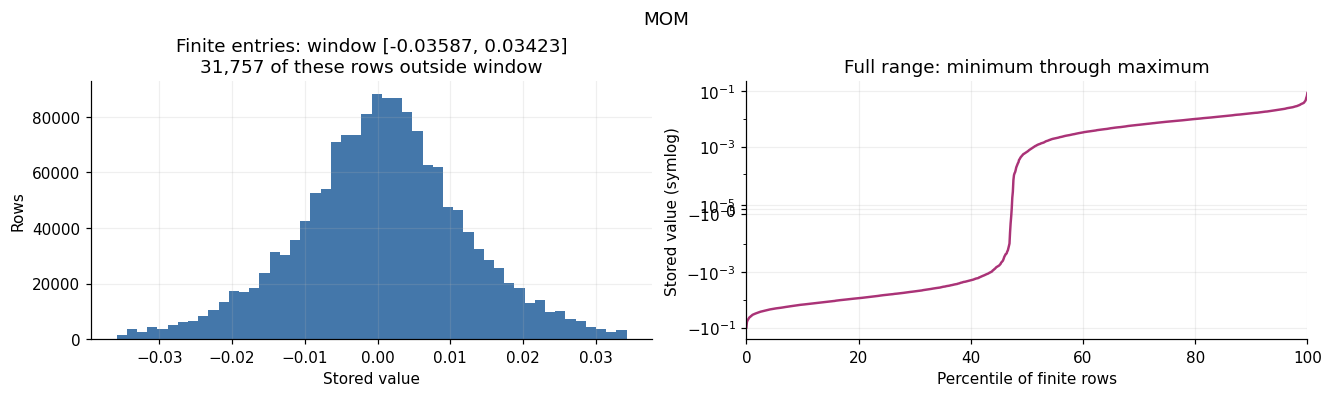

In [39]:
show_numeric('MOM')

### 37. `lnDeltaP` — Log price-change field (inferred)

The name suggests `log(P_t / P_previous)`. The underlying price series, dividend treatment, and interval are not specified. For a verified log return r, the simple return would be `exp(r) - 1`, not exactly r. Do not assume every row spans one trading day or that this is a raw-close return. Extreme values remain visible.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
lnDeltaP,1876617,1140,0,268453,819291,-10.882988,-0.122047,0.0,0.125769,9.604003


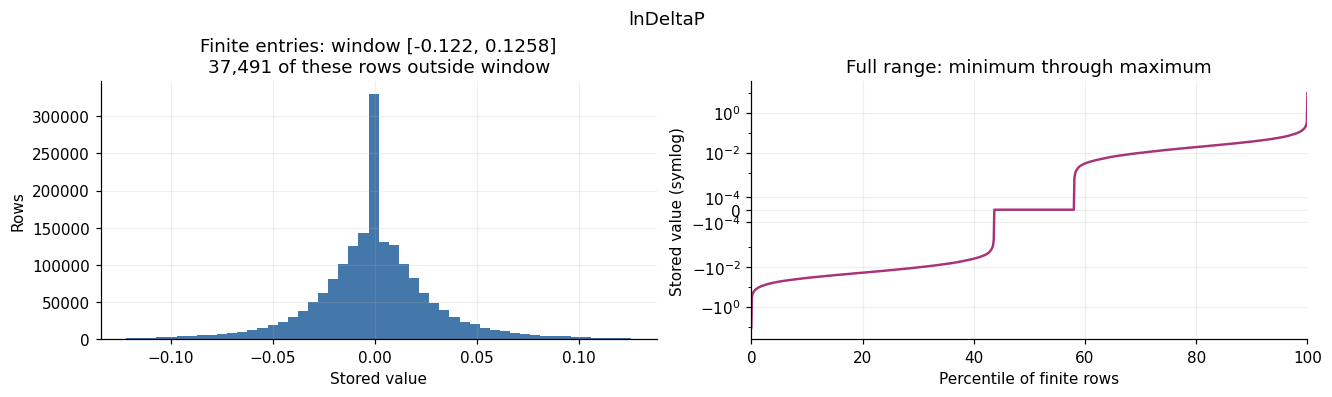

In [40]:
show_numeric('lnDeltaP')

### 38. `lnDeltaOSEBX` — OSEBX benchmark log-change field (inferred)

The name suggests a log change in an OSEBX benchmark series. The exact index version and interval alignment are undocumented. Same-date values can differ across rows, so this should not automatically be reduced to one daily return; within-date variation is counted below.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
lnDeltaOSEBX,1876617,15791,0,10626,835282,-0.684831,-0.04473,0.001017,0.037468,0.856265


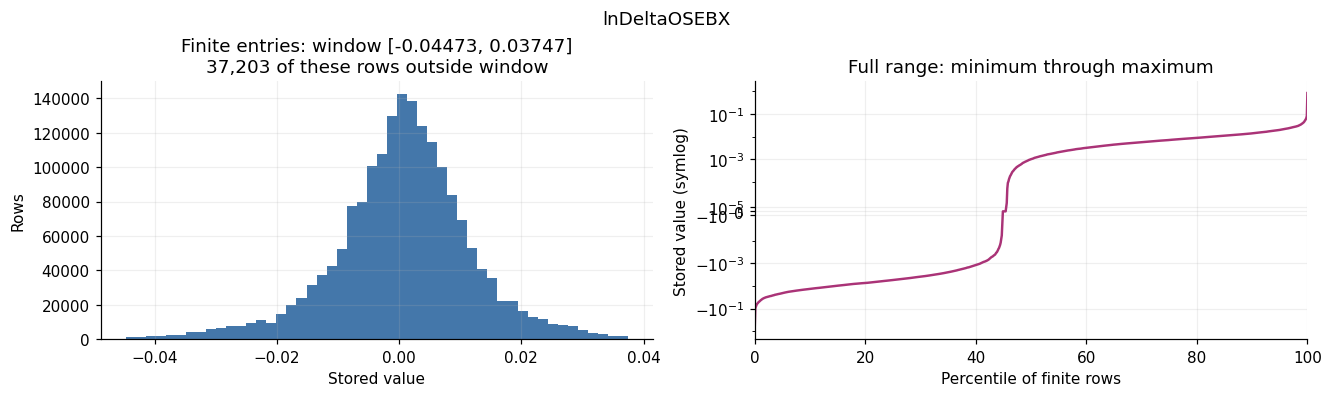

In [41]:
show_numeric('lnDeltaOSEBX')

### 39. `lnDeltaOBX` — OBX benchmark log-change field (inferred)

A second benchmark log-change field. It is distinct from `lnDeltaOSEBX`, and index composition, return version, and interval conventions are not supplied. Compare availability and within-date variation before using it as a regression benchmark.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
lnDeltaOBX,1876617,280259,0,8741,726921,-0.68487,-0.045066,0.000933,0.038185,0.880739


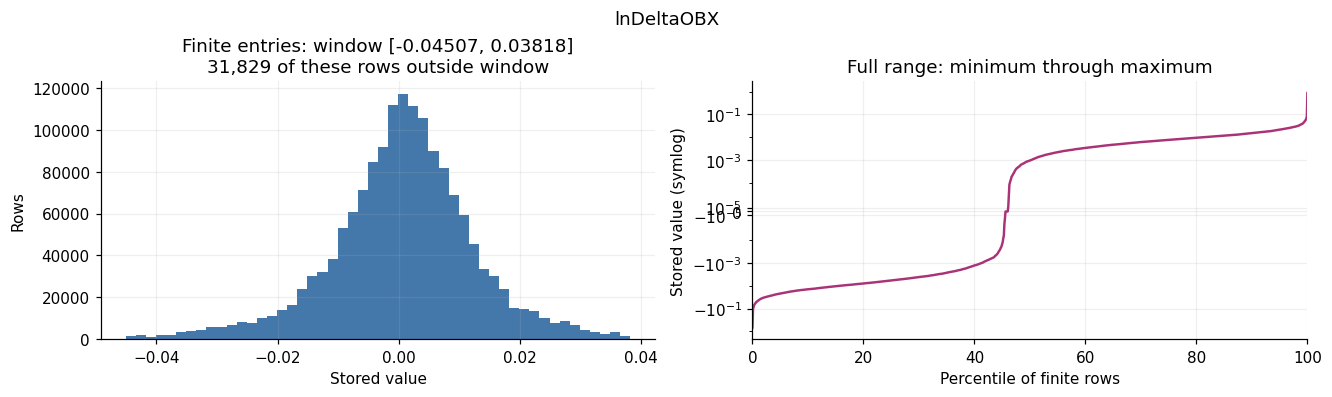

In [42]:
show_numeric('lnDeltaOBX')

### 40. `NOWA_DayLnrate` — NOWA-related daily log-rate field (inferred)

The name indicates a NOWA-related daily logarithmic interest-rate measure. Compounding, day-count, and historical backfilling conventions are not provided. Small or negative stored values are retained; do not multiply by 100 and label the result an annual percentage rate.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
NOWA_DayLnrate,1876617,0,0,88106,8023,-4.444667e-07,0.0,0.000151,0.000659,0.002586


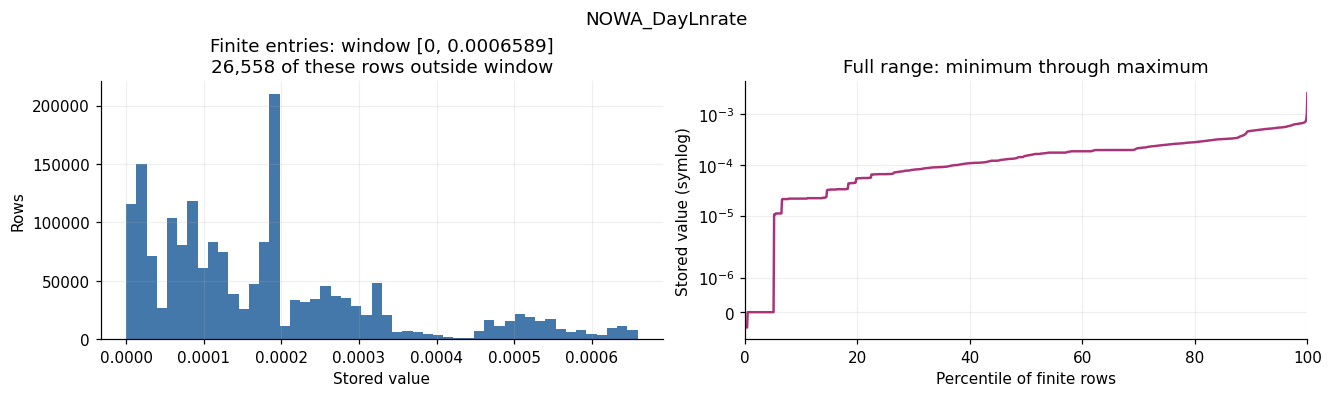

In [43]:
show_numeric('NOWA_DayLnrate')

### 41. `bills_3month_Lnrate` — Three-month bill log-rate field (inferred)

The name suggests a logarithmic rate derived from three-month bills. A three-month instrument maturity does not establish the return interval stored on each row. Day-count and conversion conventions are unverified, so the plot stays in stored units.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
bills_3month_Lnrate,1876617,82633,0,5640,6347,-7.556198e-07,5.777402e-07,0.000131,0.000578,0.001341


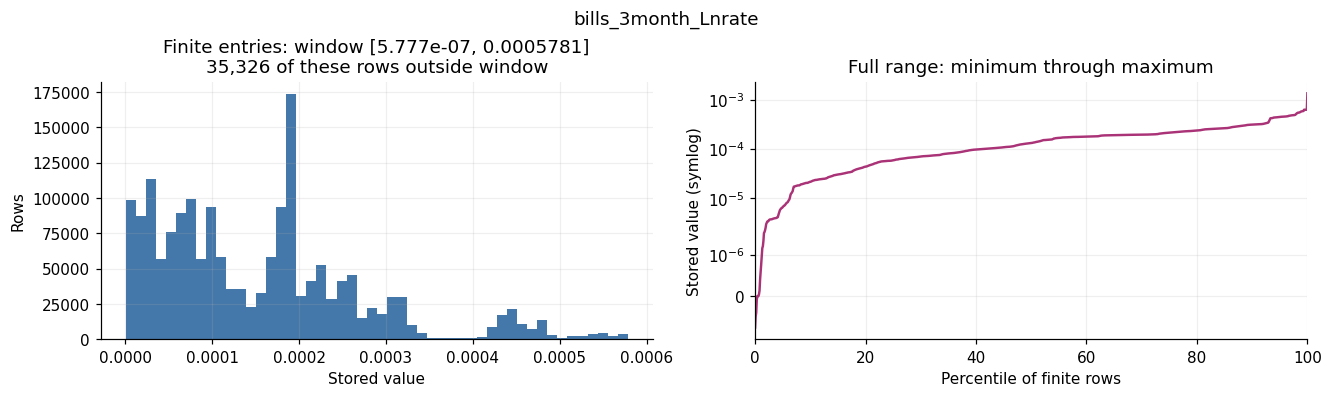

In [44]:
show_numeric('bills_3month_Lnrate')

### 42. `Sector` — Recorded sector/classification label

Categorical labels supplied by the file, including labels such as `ETF` alongside industry sectors. The classification standard and historical dating are not documented. The chart counts observations, so it does not measure the number of currently listed companies in each sector.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
Sector,1876617,1,17,16


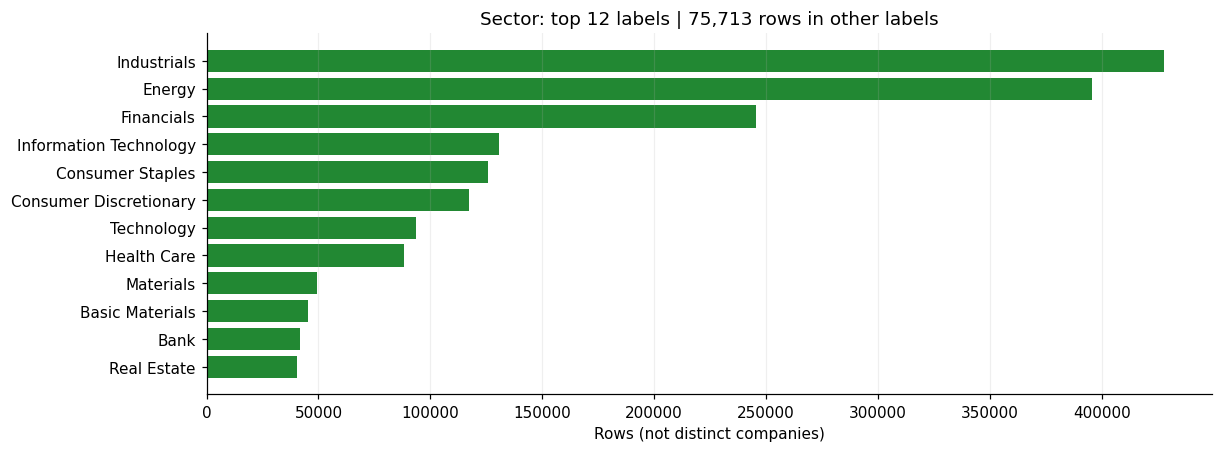

In [45]:
show_category('Sector')

### 43. `IN_OSEBX` — OSEBX membership flag (inferred)

Observed values are 0 and 1; the name suggests OSEBX index membership at the row date. The interpretation is 1 = in and 0 = out, subject to the provider's undocumented effective-date rules. Missing OSEBX-related fields should not automatically be replaced by zero for nonmembers.

,rows,missing_after_trimming,distinct_raw,distinct_after_trimming
IN_OSEBX,1876617,0,2,2


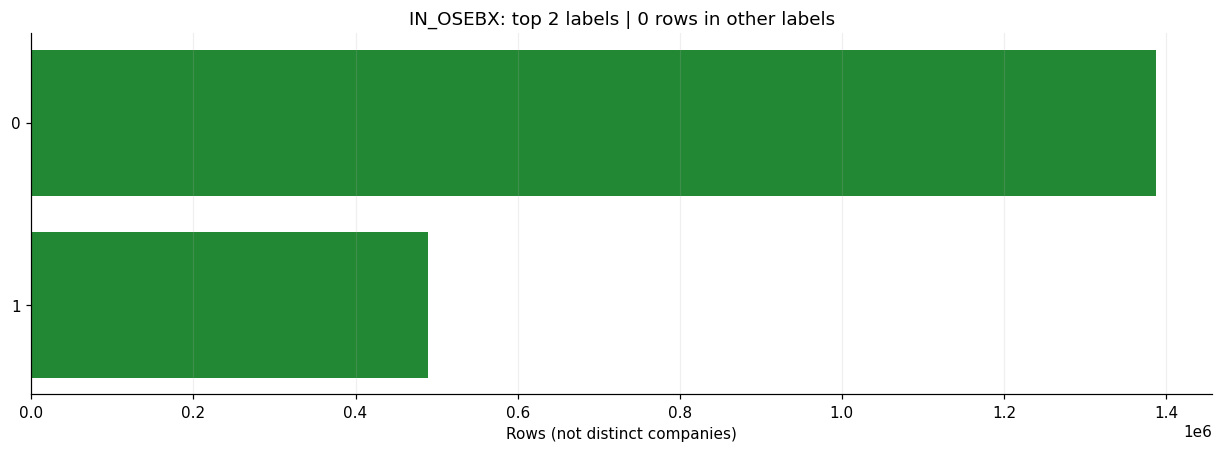

In [46]:
show_category('IN_OSEBX')

### 44. `Equity` — Accounting equity (inferred)

Interpreted as a book-equity amount, rather than market capitalization. Currency, scale, consolidation scope, fiscal period, and public-availability date are not stated. Negative equity can be economically meaningful, while extreme values still need verification. A dated row does not prove the accounting figure was known to investors then.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Equity,1876617,628013,0,8205,23299,-2.951723e+10,-5.391177e+07,875962000.0,8.127600e+10,1.014634e+15


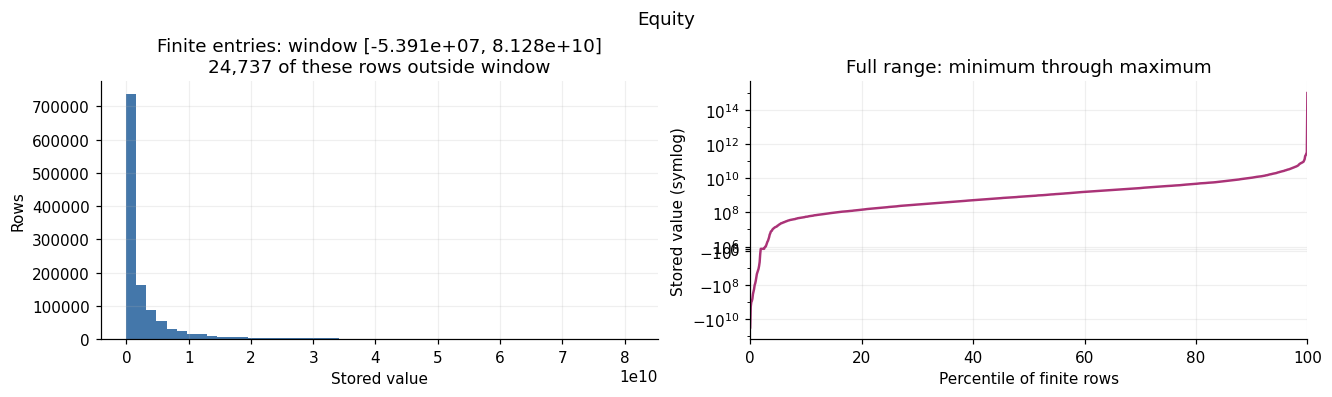

In [47]:
show_numeric('Equity')

### 45. `Debt` — Accounting debt measure (inferred)

Interpreted as an accounting debt amount. The file does not define total liabilities versus interest-bearing debt, or specify units and reporting basis. Those distinctions matter for leverage. Missing debt is not zero debt; avoid combining amounts with other fields before checking unit compatibility.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Debt,1876617,754156,0,3162,0,0.0,1.461371e+06,1.409204e+09,3.826630e+11,9.035975e+14


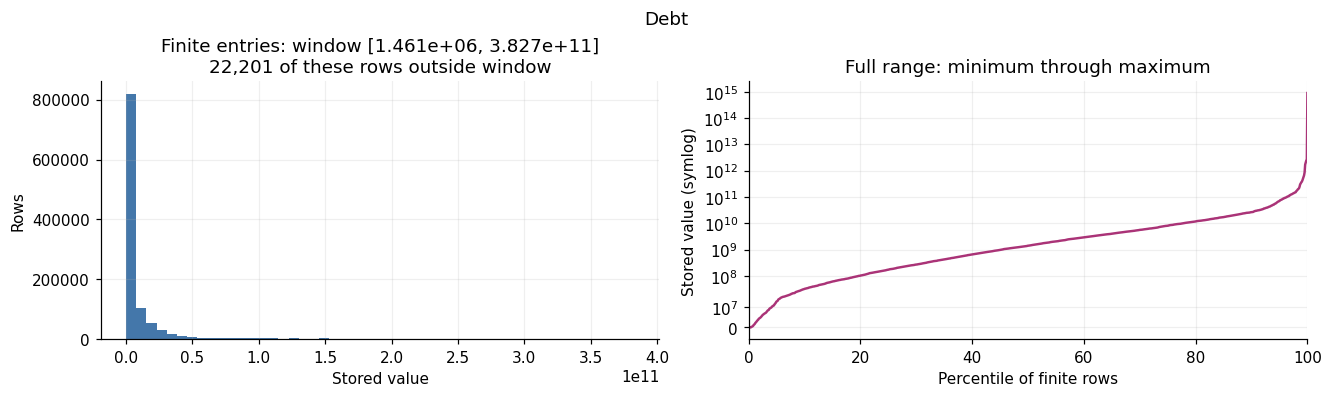

In [48]:
show_numeric('Debt')

### 46. `Earnings` — Accounting earnings measure (inferred)

An earnings amount whose period and definition are unspecified: it may not represent current annual or trailing-twelve-month net income. Negative values are retained as potential losses. Reporting lag and restatements must be resolved before any backtest uses this as information available on `Date`.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
Earnings,1876617,755089,0,14352,359384,-5.166455e+10,-2.781761e+09,48976000.0,1.637700e+10,3.894070e+12


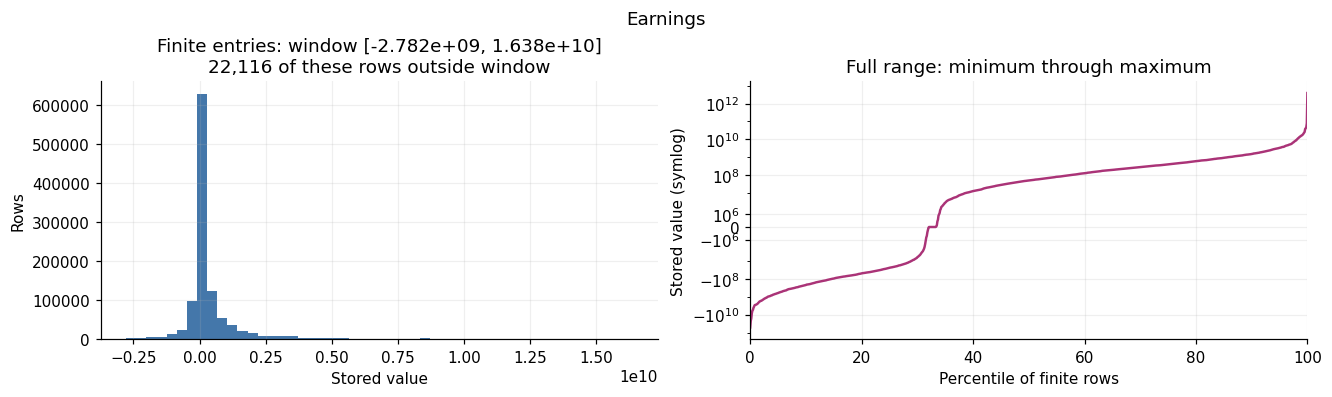

In [49]:
show_numeric('Earnings')

### 47. `debt_ratio` — Recorded leverage ratio

A dimensionless ratio by its name. The candidate `Debt / (Debt + Equity)` is tested below, rather than assumed to be the provider's formula. Values above one occur; negative equity or incompatible accounting inputs can affect such a ratio. It is not automatically a percentage or debt-to-equity ratio.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
debt_ratio,1876617,755313,0,2005,0,0.0,0.009426,0.588447,1.188682,159.111455


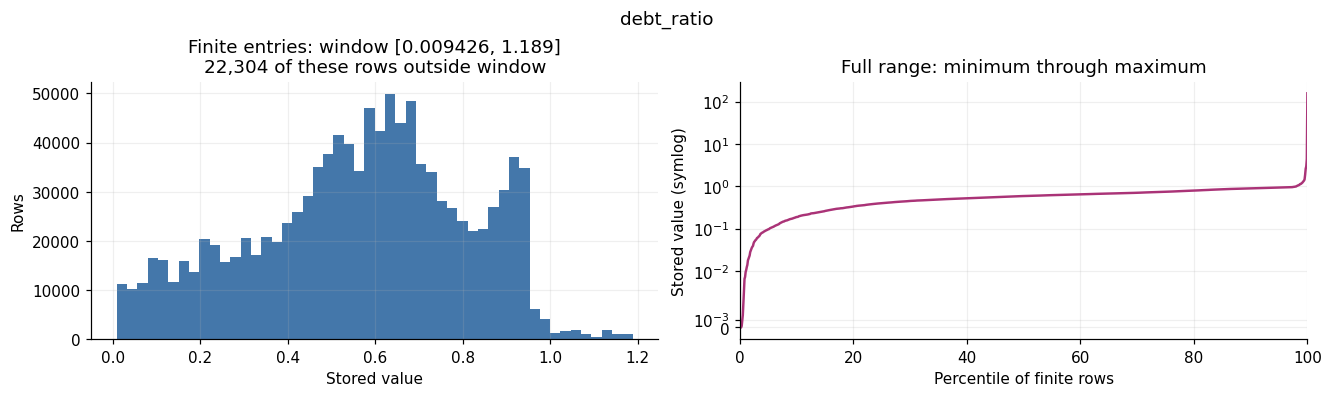

In [50]:
show_numeric('debt_ratio')

### 48. `PE` — Recorded price-to-earnings ratio (inferred)

Conventionally a dimensionless valuation multiple. Negative values can correspond to negative earnings, and values near zero earnings can become extreme. The candidate `mktcap / Earnings` is checked below, but differences can arise from earnings basis, units, reporting timing, or share-class scope. Do not treat negative PE as simply 'cheap'.

,rows,missing,nonfinite_not_missing,zero,negative,min,p01,median,p99,max
PE,1876617,769709,0,858,359252,-1.883158e+06,-317.577174,6.257022,503.922488,374153.906667


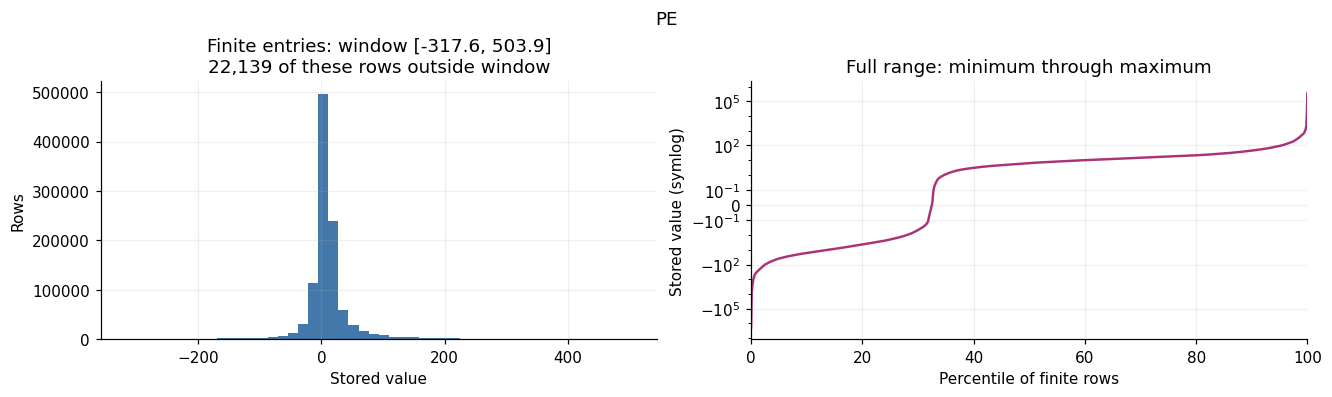

In [51]:
show_numeric('PE')

### 49. `ID` — Export record identifier

An integer label, not a date or financial measurement. Its uniqueness is checked directly. Row order is grouped in ways that need not be chronological, and numerical gaps in IDs do not demonstrate missing trading sessions. The chart shows the distribution of record multiplicities rather than a misleading price-like histogram of ID values.

,rows,missing_ID,distinct_nonmissing_ID,excess_rows_over_distinct_ID,minimum_ID,maximum_ID
0,1876617,0,1876617,0,1,1876618


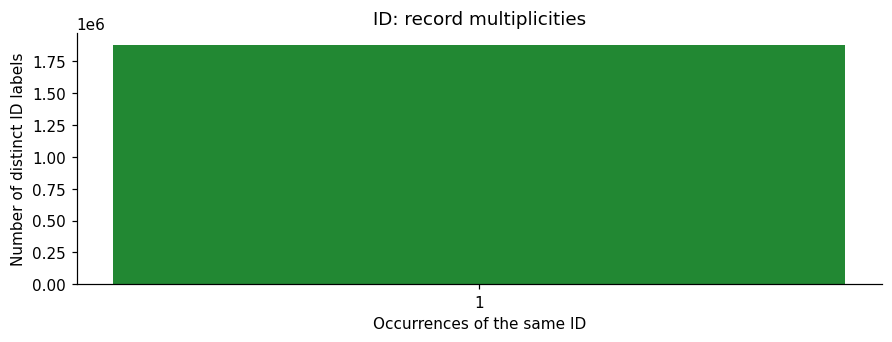

In [52]:
id_counts = data["ID"].value_counts(dropna=False)
multiplicities = id_counts.value_counts().sort_index()
display(pd.DataFrame([{
    "rows": len(data), "missing_ID": data["ID"].isna().sum(),
    "distinct_nonmissing_ID": data["ID"].nunique(),
    "excess_rows_over_distinct_ID": len(data) - len(id_counts),
    "minimum_ID": data["ID"].min(), "maximum_ID": data["ID"].max(),
}]))
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.bar(multiplicities.index.astype(str), multiplicities.values, color="#228833")
ax.set(xlabel="Occurrences of the same ID", ylabel="Number of distinct ID labels",
       title="ID: record multiplicities")
plt.show()
plt.close(fig)
visualized_columns.append("ID")

## 4. Check interpretations against the actual rows

These checks use the same unmodified CSV data. A high numerical agreement rate supports
a candidate identity on the eligible rows; it does not establish the economic definition
or its validity for other exports. A low rate is a reason to investigate, not to overwrite
the supplied column. Comparisons use relative tolerance `1e-6` and absolute tolerance
`1e-8`. Missing, nonfinite, and zero-denominator cases are excluded and counted through
the eligible-row total; the first three comparisons require positive price/volume inputs.

In [53]:
candidate_checks = []


def check_identity(label: str, observed: pd.Series, expected: pd.Series,
                   eligible: pd.Series) -> None:
    '''Measure a candidate formula without changing either source series.'''
    valid = eligible & np.isfinite(observed) & np.isfinite(expected)
    matches = np.isclose(observed[valid], expected[valid], rtol=1e-6, atol=1e-8)
    candidate_checks.append({
        "candidate": label, "eligible_rows": int(valid.sum()),
        "excluded_rows": int((~valid).sum()),
        "agreement_%": 100 * matches.mean() if matches.size else np.nan,
    })


check_identity("AdjustedPrice = Price × CorpAdj × DividendAdj", data["AdjustedPrice"],
               data["Price"] * data["CorpAdj"] * data["DividendAdj"],
               data[["Price", "CorpAdj", "DividendAdj"]].gt(0).all(axis=1))
check_identity("mktcap = Price × NumberOfShares × NOKPerForex", data["mktcap"],
               data["Price"] * data["NumberOfShares"] * data["NOKPerForex"],
               data[["Price", "NumberOfShares", "NOKPerForex"]].gt(0).all(axis=1))
check_identity("Turnover = Volume × VWAP", data["Turnover"],
               data["Volume"] * data["VolumeWeightedAveragePrice"],
               data[["Volume", "VolumeWeightedAveragePrice"]].gt(0).all(axis=1))
denominator = data["Debt"] + data["Equity"]
check_identity("debt_ratio = Debt / (Debt + Equity)", data["debt_ratio"],
               data["Debt"] / denominator.where(denominator.ne(0)), denominator.ne(0))
check_identity("PE = mktcap / Earnings", data["PE"],
               data["mktcap"] / data["Earnings"].where(data["Earnings"].ne(0)),
               data["Earnings"].ne(0))
check_identity("Price = Close", data["Price"], data["Close"], data["Close"].gt(0))
check_identity("LDividends = Dividends", data["LDividends"], data["Dividends"],
               pd.Series(True, index=data.index))
display(pd.DataFrame(candidate_checks).set_index("candidate").round(3))
print("Dividend equality includes zero-dividend rows; high agreement need not imply identical event conventions.")

,eligible_rows,excluded_rows,agreement_%
candidate,,,
AdjustedPrice = Price × CorpAdj × DividendAdj,1876617,0,100.000
mktcap = Price × NumberOfShares × NOKPerForex,1861786,14831,100.000
Turnover = Volume × VWAP,1746628,129989,93.107
debt_ratio = Debt / (Debt + Equity),1121304,755313,100.000
PE = mktcap / Earnings,1106908,769709,100.000
Price = Close,1850348,26269,100.000
LDividends = Dividends,1875477,1140,99.470


Dividend equality includes zero-dividend rows; high agreement need not imply identical event conventions.


On this file, the adjusted-price, market-cap, debt-ratio, and PE candidate identities
match every eligible row within the stated tolerance. The turnover/VWAP identity matches
about 93.1% of eligible rows, so it is not a universal identity in the export.
`Price` matches `Close` on all positive-close rows, but `Price` remains positive on rows
where `Close` is zero. This does not establish how those alternative prices were selected.

### Identifier coverage and suspicious price/volume values

Potential key duplicates count **all rows participating in a repeated key**, not just
copies beyond the first. A repeated key does not by itself prove that entire rows are
duplicates. Bid/ask placeholder-like codes and nonpositive prices are counted without
repair. A negative `lnDeltaP`, factor return, or earnings amount is not inherently invalid,
so those fields are not included in the nonpositive-price diagnostic.

In [54]:
key_checks = []
for keys in [["ID"], ["SecurityId", "Date"], ["ISIN", "Date"]]:
    complete = data[keys].notna().all(axis=1)
    key_checks.append({
        "key": " + ".join(keys), "rows_missing_key": int((~complete).sum()),
        "rows_in_repeated_complete_keys": int(data.loc[complete, keys].duplicated(keep=False).sum()),
    })
display(pd.DataFrame(key_checks).set_index("key"))

quote_columns = ["BestBidPrice", "BestAskPrice", "Open", "High", "Low", "Close",
                 "VolumeWeightedAveragePrice", "Price", "AdjustedPrice", "Volume"]
quality = pd.DataFrame({
    "missing": data[quote_columns].isna().sum(),
    "zero": data[quote_columns].eq(0).sum(),
    "negative": data[quote_columns].lt(0).sum(),
    "equals_-999999999": data[quote_columns].eq(-999999999).sum(),
})
display(quality)
valid_quotes = data[["BestBidPrice", "BestAskPrice"]].gt(0).all(axis=1)
valid_range = data[["High", "Low"]].gt(0).all(axis=1)
print(f"Ask below bid: {(valid_quotes & data['BestAskPrice'].lt(data['BestBidPrice'])).sum():,} / {valid_quotes.sum():,} positive quote pairs")
print(f"High below low: {(valid_range & data['High'].lt(data['Low'])).sum():,} / {valid_range.sum():,} positive high/low pairs")

,rows_missing_key,rows_in_repeated_complete_keys
key,,
ID,0,0
SecurityId + Date,203065,13202
ISIN + Date,0,21282


,missing,zero,negative,equals_-999999999
BestBidPrice,11697,8331,1207,1207
BestAskPrice,16892,4979,695,695
Open,103597,26269,0,0
High,9,26269,0,0
Low,9,26269,0,0
Close,0,26269,0,0
VolumeWeightedAveragePrice,103714,0,5,0
Price,0,0,0,0
AdjustedPrice,0,0,0,0
Volume,71,26269,5,0


Ask below bid: 453 / 1,836,352 positive quote pairs
High below low: 0 / 1,850,339 positive high/low pairs


### Are factor and benchmark fields constant within a date?

The number of distinct nonmissing values per date is checked for the factor, benchmark,
and interest-rate fields. If more than one value occurs, selecting the first row or
averaging the rows would discard information. Even very small floating-point differences
count as distinct in this diagnostic. The CSV alone cannot establish whether differences
reflect interval alignment, source conventions, or errors. No daily series is synthesized.

In [55]:
market_columns = ["SMB", "HML", "LIQ", "MOM", "lnDeltaOSEBX", "lnDeltaOBX",
                  "NOWA_DayLnrate", "bills_3month_Lnrate"]
distinct_per_date = data.groupby("Date")[market_columns].nunique()
date_consistency = pd.DataFrame({
    "dates_with_values": distinct_per_date.gt(0).sum(),
    "dates_with_multiple_values": distinct_per_date.gt(1).sum(),
    "max_distinct_values_on_one_date": distinct_per_date.max(),
})
display(date_consistency)

,dates_with_values,dates_with_multiple_values,max_distinct_values_on_one_date
SMB,7708,0,1
HML,7244,0,1
LIQ,7708,0,1
MOM,7708,0,1
lnDeltaOSEBX,10992,10363,15
lnDeltaOBX,7729,7100,15
NOWA_DayLnrate,11745,0,1
bills_3month_Lnrate,9961,0,1


## 5. Put price, adjustments, and dividends on a timeline

For context, select the ISIN with the most recorded dates (lexicographic tie-break).
This is a descriptive example, not a claim of representativeness. Only dates with exactly
one row for that ISIN are plotted, avoiding an arbitrary aggregation of repeated records.
Excluded ambiguous dates are reported. No values are forward-filled; lines connect
recorded observations and can span calendar gaps.

The panels separate raw price, adjusted price, adjustment factors, and nonzero dividend
entries because their scales and meanings differ. Adjusted-price normalization can make
raw and adjusted levels look very different without implying a corresponding cash loss.

Example ISIN: NO0005052605; names: ['Norsk Hydro', 'NORSK HYDRO']
Ambiguous dates excluded: 0 (0 rows)


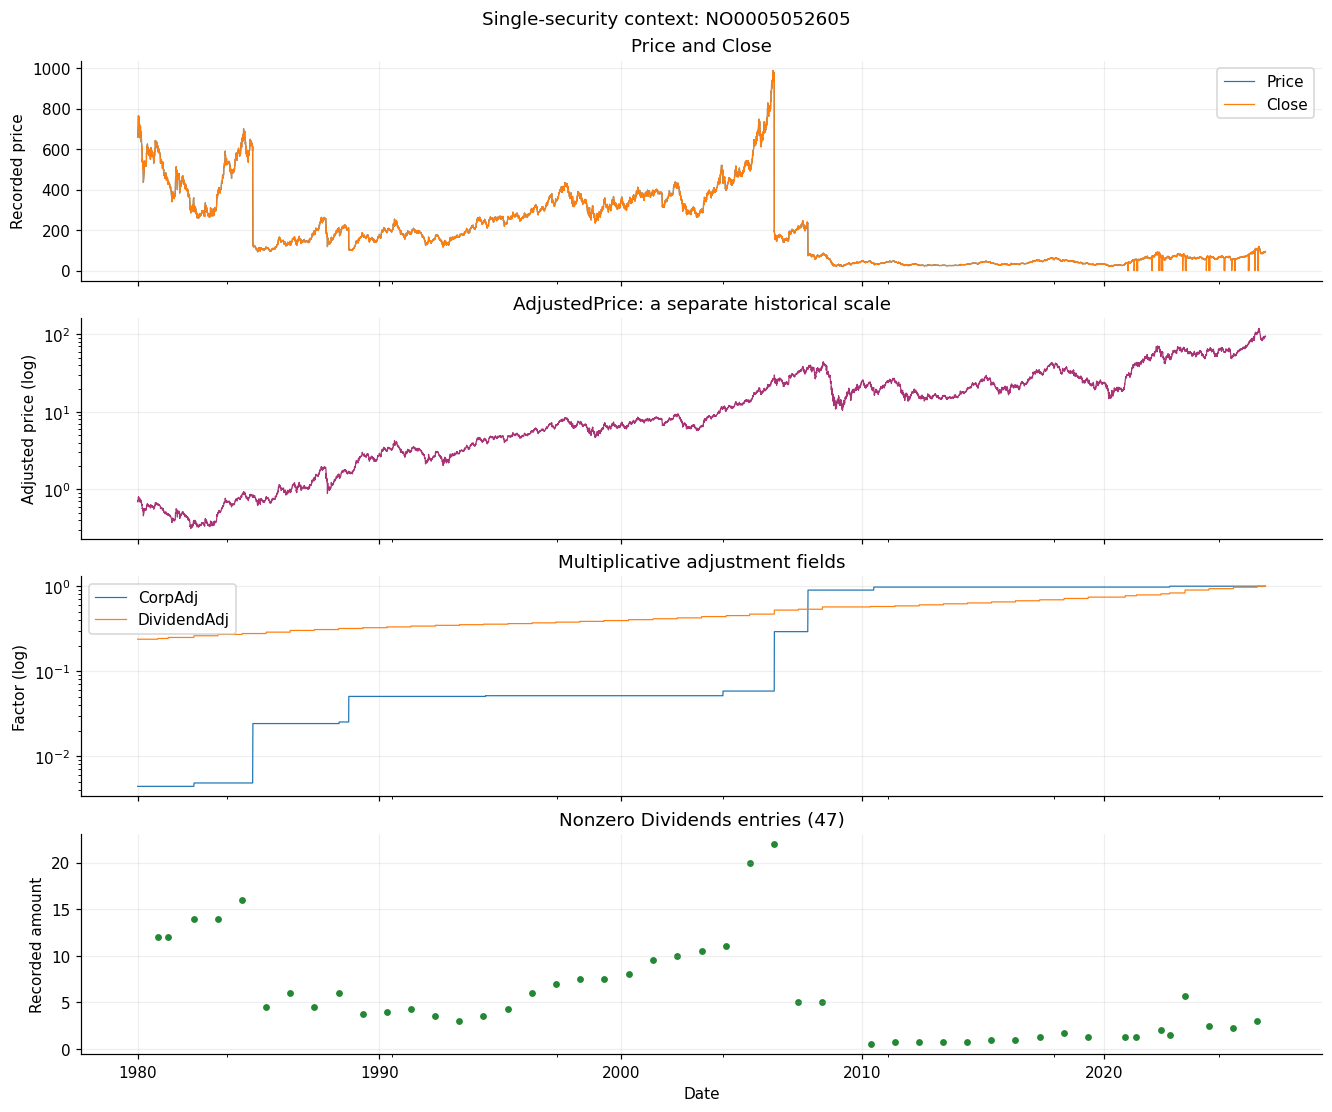

In [56]:
coverage = data.groupby("ISIN")["Date"].nunique().sort_index().sort_values(ascending=False, kind="stable")
example_isin = coverage.index[0]
example = data.loc[data["ISIN"].eq(example_isin)].sort_values("Date")
ambiguous = example["Date"].duplicated(keep=False)
print(f"Example ISIN: {example_isin}; names: {example['Name'].str.strip().unique().tolist()}")
print(f"Ambiguous dates excluded: {example.loc[ambiguous, 'Date'].nunique():,} ({ambiguous.sum():,} rows)")
example = example.loc[~ambiguous].set_index("Date")

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, constrained_layout=True)
example[["Price", "Close"]].plot(ax=axes[0], linewidth=0.8)
axes[0].set(ylabel="Recorded price", title="Price and Close")
example["AdjustedPrice"].plot(ax=axes[1], color="#AA3377", linewidth=0.8)
axes[1].set_yscale("log")
axes[1].set(ylabel="Adjusted price (log)", title="AdjustedPrice: a separate historical scale")
example[["CorpAdj", "DividendAdj"]].plot(ax=axes[2], linewidth=0.8, logy=True)
axes[2].set(ylabel="Factor (log)", title="Multiplicative adjustment fields")
events = example.loc[example["Dividends"].notna() & example["Dividends"].ne(0), "Dividends"]
axes[3].scatter(events.index, events.values, s=12, color="#228833")
axes[3].set(xlabel="Date", ylabel="Recorded amount", title=f"Nonzero Dividends entries ({len(events):,})")
for ax in axes:
    ax.grid(alpha=0.2)
fig.suptitle(f"Single-security context: {example_isin}")
plt.show()
plt.close(fig)

## 6. Coverage check and limits

The check below confirms that every source column has its own explanation and plot.
The notebook is an inventory of the supplied file, not a cleaned research dataset.
Before modeling, resolve placeholder codes, duplicate observation keys, the intended
return intervals, and the provider's definitions of the accounting and factor fields.
Accounting publication lags and adjustment conventions matter for avoiding future
information in historical analyses. No such conventions have been filled in here.

In [57]:
assert len(visualized_columns) == data.shape[1]
assert set(visualized_columns) == set(data.columns)
assert len(set(visualized_columns)) == len(visualized_columns)
print(f"Explained and visualized all {len(visualized_columns)} source columns.")
print(f"Only dataset used: {data_path.name}")

Explained and visualized all 49 source columns.
Only dataset used: BMG9156K1018_10.09.2026_14.59.34.csv
